# Final GLD965 MA5 research package
Five direct horizons, raw compact LightGBM and selected/all calibrators. This notebook loads bundled data/models and reports. Base models are TRAIN-fitted; calibrators fit earlier TEST and regression selection uses later TEST RMSE. OOT was previously inspected. This package supports research inference, not an accepted live forecasting claim.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
from build_package import infer
P=Path.cwd()
display(pd.read_csv(P/'evidence/Dataset_description.csv'))
display(pd.read_csv(P/'data/Schedule.csv'))

,partition,horizon,n,positive,nonpositive,positive_rate,first,last,target_mean,target_std,target_min,target_max,change_mean,change_std
0,TRAIN,1,24194,12933,11261,0.534554,2025-01-01 01:15:00+07:00,2026-03-06 16:30:00+07:00,56271.293040,9264.468883,42453.0,81758.6,0.893635,35.640719
1,TEST,1,10372,5121,5251,0.493733,2026-03-06 18:00:00+07:00,2026-09-05 02:45:00+07:00,68989.656884,3737.049282,62364.8,78173.0,-0.470922,43.352769
2,OOT,1,3629,1729,1900,0.476440,2026-09-07 07:30:00+07:00,2026-11-07 03:45:00+07:00,66150.327473,1678.056041,62015.8,69095.0,-0.741196,31.070472
3,TRAIN,2,24194,13030,11164,0.538563,2025-01-01 01:15:00+07:00,2026-03-06 16:30:00+07:00,56272.115186,9264.155854,42451.4,81758.6,1.715781,67.406601
4,TEST,2,10372,5071,5301,0.488912,2026-03-06 18:00:00+07:00,2026-09-05 02:45:00+07:00,68989.037968,3736.664655,62364.8,78173.0,-1.089838,81.751183
5,OOT,2,3629,1726,1903,0.475613,2026-09-07 07:30:00+07:00,2026-11-07 03:45:00+07:00,66149.534693,1678.106906,62015.8,69095.0,-1.533976,58.600623
6,TRAIN,3,24194,13111,11083,0.541911,2025-01-01 01:15:00+07:00,2026-03-06 16:30:00+07:00,56272.853319,9263.794036,42451.4,81758.6,2.453914,96.183663
7,TEST,3,10372,5090,5282,0.490744,2026-03-06 18:00:00+07:00,2026-09-05 02:45:00+07:00,68988.222484,3736.171323,62364.8,78173.0,-1.905322,116.928451
8,OOT,3,3629,1699,1930,0.468173,2026-09-07 07:30:00+07:00,2026-11-07 03:45:00+07:00,66148.691265,1678.096951,62015.8,69095.0,-2.377404,83.812963
9,TRAIN,4,24194,13110,11084,0.541870,2025-01-01 01:15:00+07:00,2026-03-06 16:30:00+07:00,56273.481508,9263.344633,42451.4,81758.6,3.082103,121.773864


,partition,rows,first,last,first_label_h5,last_label_h5
0,TRAIN,24194,2024-12-31 18:15:00+00:00,2026-03-06 09:30:00+00:00,2024-12-31 19:30:00+00:00,2026-03-06 10:45:00+00:00
1,TEST,10372,2026-03-06 11:00:00+00:00,2026-09-04 19:45:00+00:00,2026-03-06 12:15:00+00:00,2026-09-04 21:00:00+00:00
2,OOT,3629,2026-09-07 00:30:00+00:00,2026-11-06 20:45:00+00:00,2026-09-07 01:45:00+00:00,2026-11-06 22:00:00+00:00


## Model settings and feature weights — Excel 3.2 / 3.7
All retained features satisfy 5%–70% TRAIN gain limits. Gain shares are not causal effects or signed coefficients.

In [2]:
display(pd.read_csv(P/'evidence/Model_parameters.csv'))
display(pd.read_csv(P/'evidence/Regression_features.csv'))
display(pd.read_csv(P/'evidence/Classification_features.csv'))

,horizon,task,features,model_parameters,target_mean,target_scale,calibration
0,1,regression,"[""price_to_ma5"", ""body"", ""price_to_ma7"", ""pric...","{""boosting_type"": ""gbdt"", ""class_weight"": null...",0.000003,0.000248,linear
1,1,classification,"[""price_to_ma7"", ""price_to_ma5"", ""momentum5"", ...","{""boosting_type"": ""gbdt"", ""class_weight"": null...",NaN,NaN,all four retained
2,2,regression,"[""price_to_ma7"", ""body"", ""hour_sin""]","{""boosting_type"": ""gbdt"", ""class_weight"": null...",0.000009,0.000549,linear
3,2,classification,"[""log_return_lag0"", ""body"", ""price_to_ma15"", ""...","{""boosting_type"": ""gbdt"", ""class_weight"": null...",NaN,NaN,all four retained
4,3,regression,"[""body"", ""price_to_ma5"", ""hour_sin"", ""return_m...","{""boosting_type"": ""gbdt"", ""class_weight"": null...",0.000017,0.000911,linear
5,3,classification,"[""price_to_ma7"", ""momentum5"", ""log_return_lag1""]","{""boosting_type"": ""gbdt"", ""class_weight"": null...",NaN,NaN,all four retained
6,4,regression,"[""body"", ""price_to_ma7"", ""log_return_lag0"", ""p...","{""boosting_type"": ""gbdt"", ""class_weight"": null...",0.000027,0.001323,linear
7,4,classification,"[""price_to_ma7"", ""momentum5"", ""log_return_lag0""]","{""boosting_type"": ""gbdt"", ""class_weight"": null...",NaN,NaN,all four retained
8,5,regression,"[""log_return_lag0"", ""price_to_ma5"", ""hour_sin""...","{""boosting_type"": ""gbdt"", ""class_weight"": null...",0.000037,0.001777,linear
9,5,classification,"[""price_to_ma7"", ""momentum5"", ""log_return_lag0""]","{""boosting_type"": ""gbdt"", ""class_weight"": null...",NaN,NaN,all four retained


,horizon,task,feature,gain_share,above_5pct,below_70pct
0,1,regression,price_to_ma5,0.232262,True,True
1,1,regression,body,0.499572,True,True
2,1,regression,price_to_ma7,0.104290,True,True
3,1,regression,price_to_ma15,0.075397,True,True
4,1,regression,hour_sin,0.088478,True,True
5,2,regression,price_to_ma7,0.210325,True,True
6,2,regression,body,0.673863,True,True
7,2,regression,hour_sin,0.115812,True,True
8,3,regression,body,0.337985,True,True
9,3,regression,price_to_ma5,0.313811,True,True


,horizon,task,feature,gain_share,above_5pct,below_70pct
0,1,classification,price_to_ma7,0.537481,True,True
1,1,classification,price_to_ma5,0.325600,True,True
2,1,classification,momentum5,0.075937,True,True
3,1,classification,log_return_lag0,0.060983,True,True
4,2,classification,log_return_lag0,0.143328,True,True
5,2,classification,body,0.095380,True,True
6,2,classification,price_to_ma15,0.422875,True,True
7,2,classification,mts_xauusd_15m_return_lag1,0.168747,True,True
8,2,classification,mts9999_15m_return_lag5,0.169669,True,True
9,3,classification,price_to_ma7,0.320005,True,True


## Performance, overfitting and calibration — Excel 3.3 / 3.8
Calibrated TRAIN uses later TEST-fitted parameters retrospectively. Full TEST mixes calibrator fitting and evaluation; CAL_VALID and OOT are the relevant later comparisons. A 2-point gap screen is a convention, not proof of no overfitting.

In [3]:
display(pd.read_csv(P/'evidence/Regression_performance.csv'))
display(pd.read_csv(P/'evidence/Classification_performance.csv'))
display(pd.read_csv(P/'evidence/Stability_checks.csv'))
display(pd.read_csv(P/'evidence/Regression_selection.csv'))

,partition,horizon,method,selected,n,RMSE,MAE,mean_error,relative_RMSE,skill_vs_structural
0,TRAIN,1,raw,False,24194,16.176962,8.872183,0.190346,0.998777,0.002444
1,TRAIN,1,isotonic,False,24194,12376.909659,10037.226213,9998.832591,764.159203,-583938.287163
2,TRAIN,1,linear,True,24194,16.269189,9.074989,1.433727,1.004471,-0.008963
3,TRAIN,1,quadratic,False,24194,36.019240,29.918918,25.897140,2.223853,-3.945524
4,TRAIN,1,cubic,False,24194,367.006528,275.099794,272.129895,22.659244,-512.441339
...,...,...,...,...,...,...,...,...,...,...
145,CAL_VALID,5,isotonic,False,5156,1080.877996,772.588491,731.775202,8.597237,-72.912479
146,CAL_VALID,5,linear,True,5156,125.871056,89.609143,5.952452,1.001171,-0.002343
147,CAL_VALID,5,quadratic,False,5156,141.496163,107.501691,54.970126,1.125452,-0.266642
148,CAL_VALID,5,cubic,False,5156,229.081817,185.947291,150.588532,1.822103,-2.320058


,partition,horizon,method,n,accuracy,balanced_accuracy,precision,recall,TN,FP,FN,TP,actual_positive_rate,predicted_positive_rate,mean_predicted_probability,Brier,ECE,log_loss
0,TRAIN,1,raw,24194,0.809374,0.807839,0.816412,0.830047,8847,2414,2198,10735,0.534554,0.543482,0.534608,0.132895,0.009519,0.414576
1,TRAIN,1,isotonic,24194,0.809250,0.807936,0.818161,0.826954,8884,2377,2238,10695,0.534554,0.540299,0.522704,0.135744,0.034055,0.423680
2,TRAIN,1,linear,24194,0.809292,0.808216,0.820233,0.823784,8926,2335,2279,10654,0.534554,0.536869,0.523080,0.133862,0.029208,0.420961
3,TRAIN,1,quadratic,24194,0.809209,0.807978,0.818830,0.825794,8898,2363,2253,10680,0.534554,0.539101,0.523480,0.133867,0.029012,0.421021
4,TRAIN,1,cubic,24194,0.809333,0.808226,0.820000,0.824248,8921,2340,2273,10660,0.534554,0.537323,0.523107,0.134673,0.036953,0.421444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,CAL_VALID,5,raw,5156,0.698216,0.699131,0.674716,0.734369,1756,889,667,1844,0.487005,0.530062,0.527292,0.196602,0.040286,0.576834
121,CAL_VALID,5,isotonic,5156,0.699379,0.699277,0.689846,0.695341,1860,785,765,1746,0.487005,0.490884,0.481390,0.195789,0.025452,0.575258
122,CAL_VALID,5,linear,5156,0.702095,0.701399,0.702031,0.674632,1926,719,817,1694,0.487005,0.467998,0.481108,0.195737,0.028426,0.575884
123,CAL_VALID,5,quadratic,5156,0.702483,0.701505,0.707255,0.663879,1955,690,844,1667,0.487005,0.457137,0.481230,0.195574,0.028238,0.575526


,horizon,task,method,TRAIN,TEST,OOT,train_test_gap,train_oot_gap,within_2point_screen,interpretation
0,1,regression,cubic,22.659244,1.118696,1.329479,-21.540548,-21.329765,True,Calibrated TRAIN uses later TEST parameters; t...
1,1,regression,isotonic,764.159203,27.899082,49.748807,-736.260121,-714.410395,True,Calibrated TRAIN uses later TEST parameters; t...
2,1,regression,linear,1.004471,0.998918,0.997844,-0.005554,-0.006628,True,Calibrated TRAIN uses later TEST parameters; t...
3,1,regression,quadratic,2.223853,1.007870,1.028509,-1.215984,-1.195344,True,Calibrated TRAIN uses later TEST parameters; t...
4,1,regression,raw,0.998777,0.999582,0.998351,0.000804,-0.000426,True,Raw base-model stability check; gap threshold ...
5,2,regression,cubic,27.030697,1.182644,1.489319,-25.848052,-25.541378,True,Calibrated TRAIN uses later TEST parameters; t...
6,2,regression,isotonic,341.962947,13.094234,23.470497,-328.868713,-318.492450,True,Calibrated TRAIN uses later TEST parameters; t...
7,2,regression,linear,1.010610,0.998727,0.998626,-0.011882,-0.011983,True,Calibrated TRAIN uses later TEST parameters; t...
8,2,regression,quadratic,2.806027,1.015463,1.055006,-1.790563,-1.751020,True,Calibrated TRAIN uses later TEST parameters; t...
9,2,regression,raw,0.999136,0.999632,0.998930,0.000496,-0.000206,True,Raw base-model stability check; gap threshold ...


,horizon,selected_method,validation_RMSE,raw_validation_RMSE
0,1,linear,17.439757,17.444823
1,2,linear,38.443555,38.452504
2,3,linear,63.900696,63.911102
3,4,linear,92.999825,93.034553
4,5,linear,125.871056,125.920229


## Reproduce inference from bundled files — Excel 3.4
This checks actual model predictions against the saved package outputs on OOT. No fitting is performed. Classification retains all four calibrators; linear is the selected regression method for each horizon.

In [4]:
oot=pd.read_csv(P/'data/OOT_X_y.csv.gz',low_memory=False)
for h in range(1,6):
    saved=pd.read_csv(P/f'data/predictions_h{h}.csv.gz').query('partition=="OOT"')
    r=infer(oot,h,'regression'); c=infer(oot,h,'classification')
    np.testing.assert_allclose(r['raw'],saved.regression_raw,rtol=1e-10)
    np.testing.assert_allclose(r['linear'],saved.regression_calibrated,rtol=1e-10)
    for name in c: np.testing.assert_allclose(c[name],saved['prob_'+name],rtol=1e-10)
print('All five horizons reproduce raw and calibrated forecasts from bundled models.')

All five horizons reproduce raw and calibrated forecasts from bundled models.


## Horizon 1: 15 minutes — Excel 3.5–3.10
Charts cover TRAIN, TEST and OOT. Monthly boundary samples can be partial. Price lines break at market gaps. Classification panels distinguish predicted positive-class share from average predicted probability. Fixed raw-TRAIN probability deciles define ECE across all methods/sets.

raw_regression


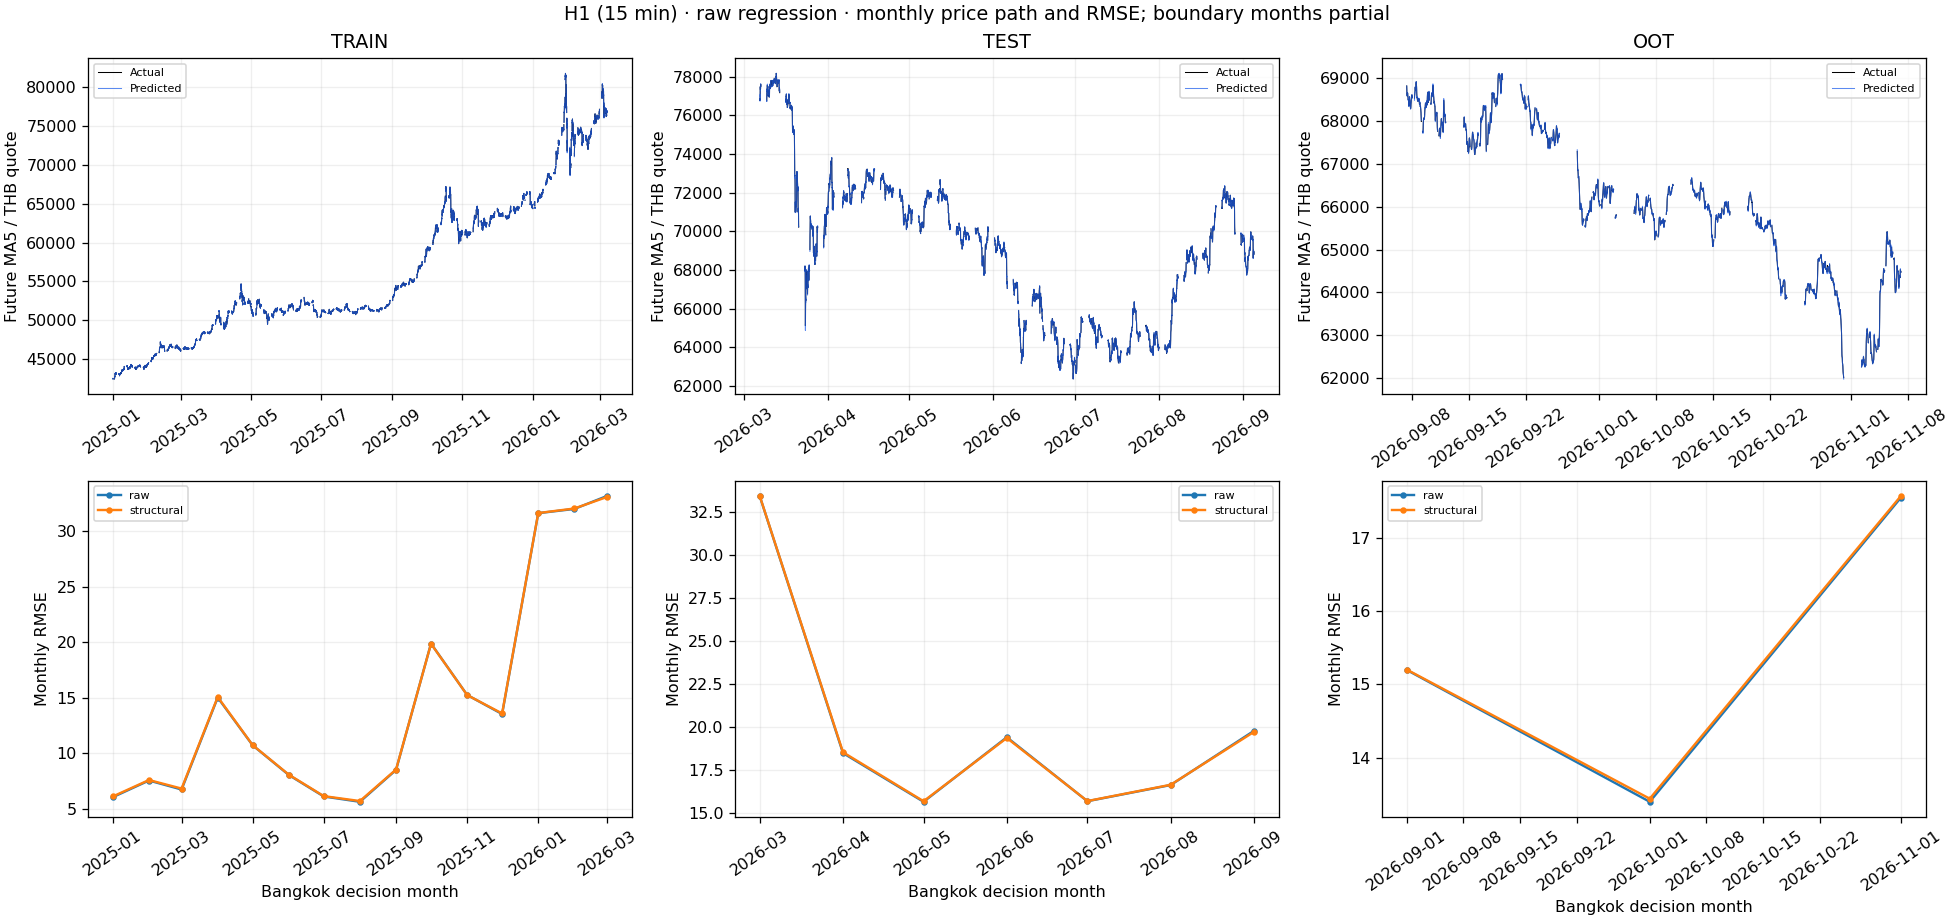

raw_classification


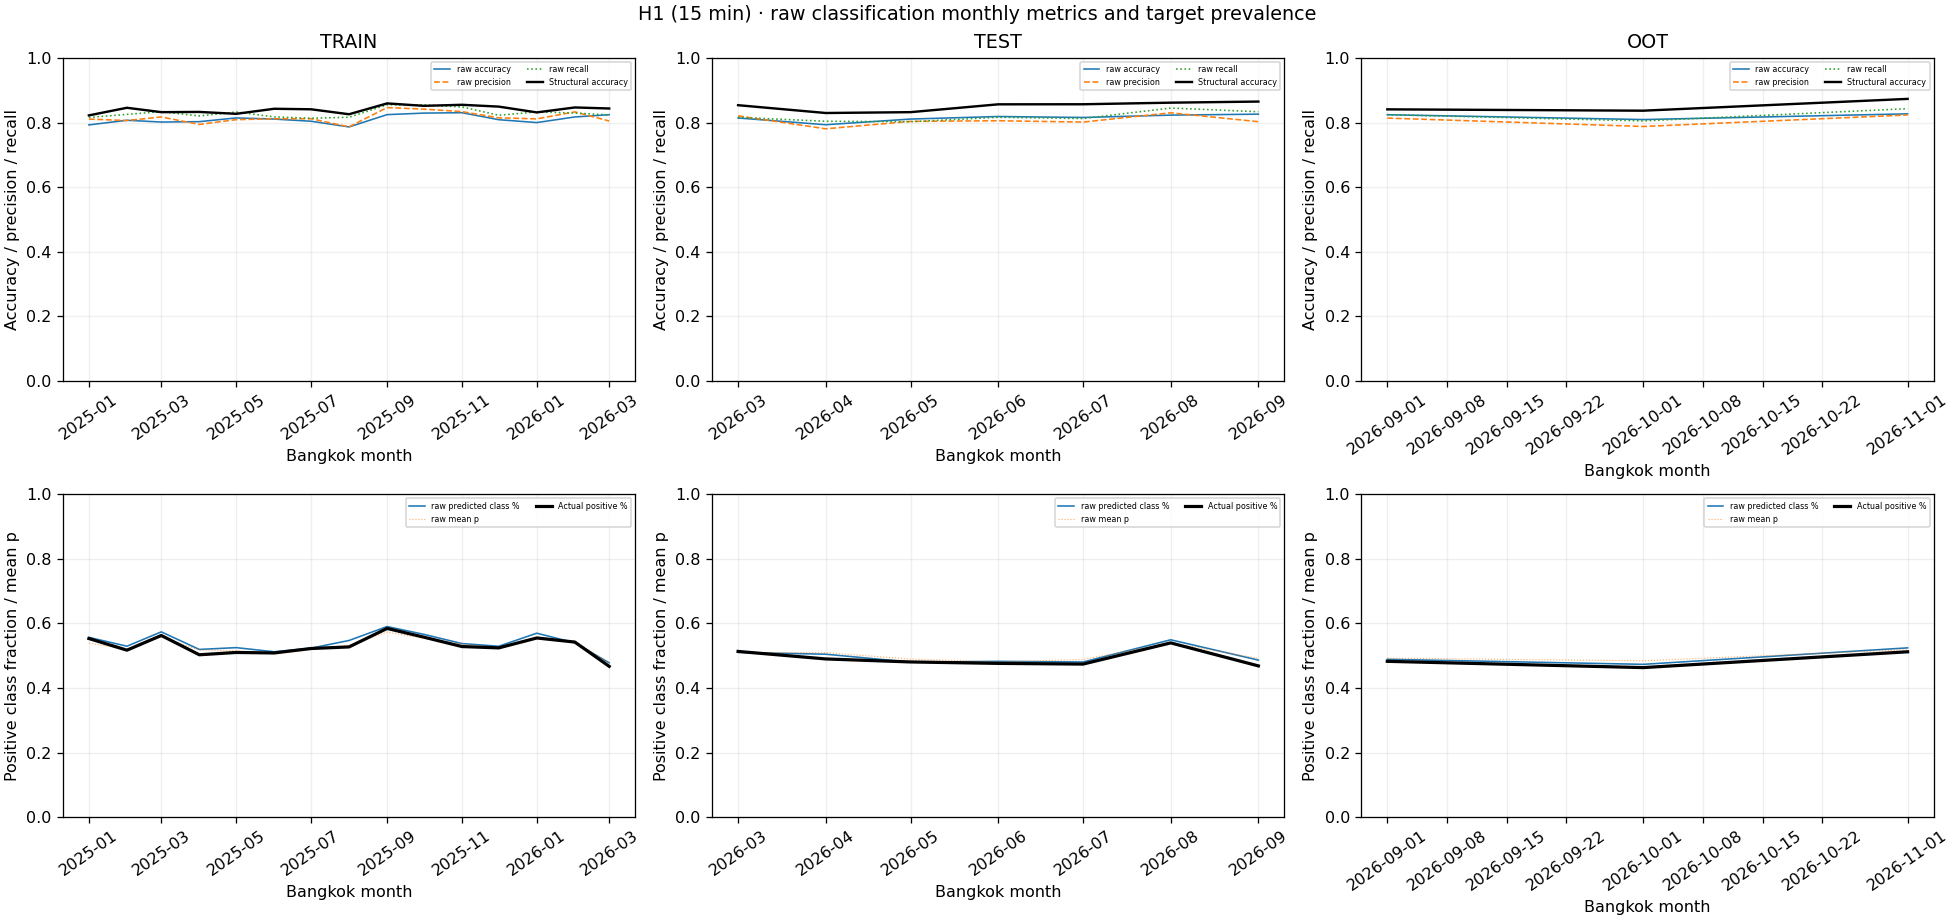

calibration


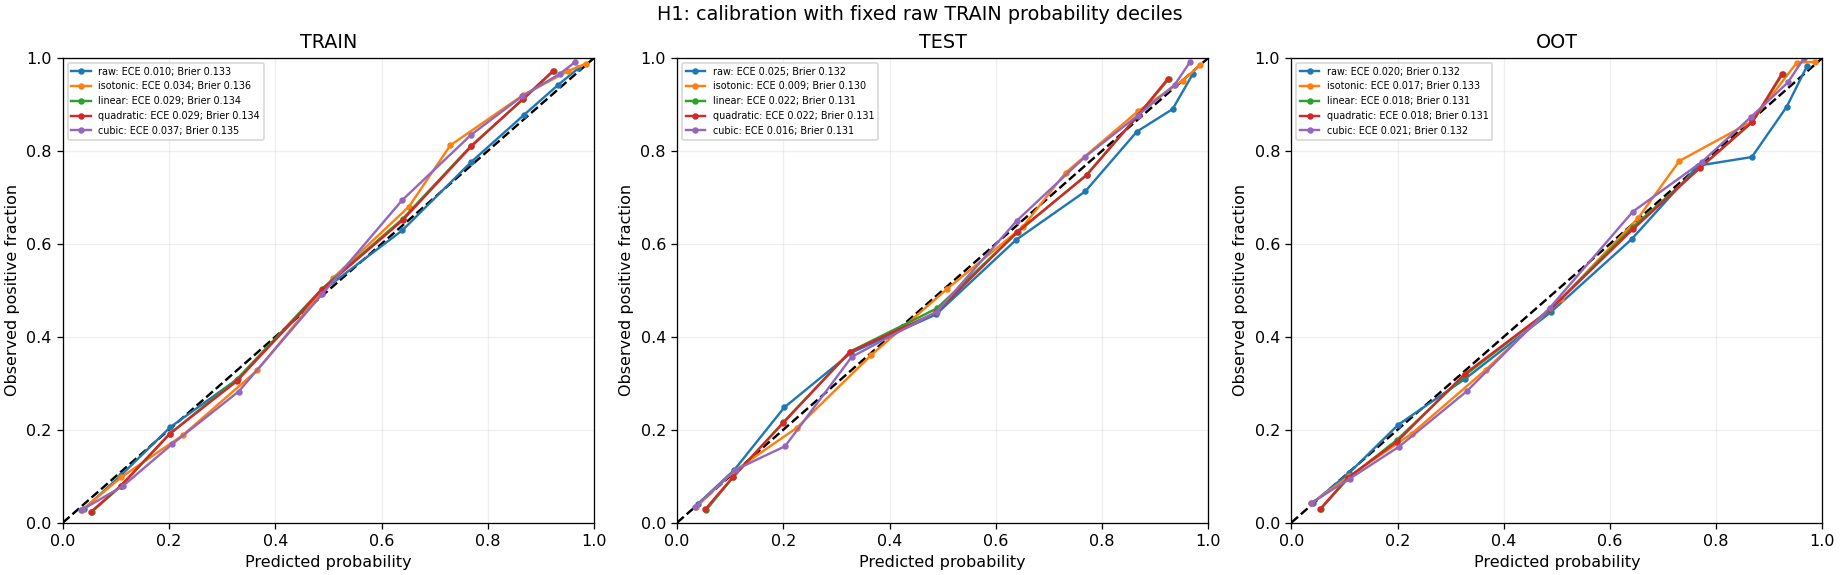

calibrated_regression


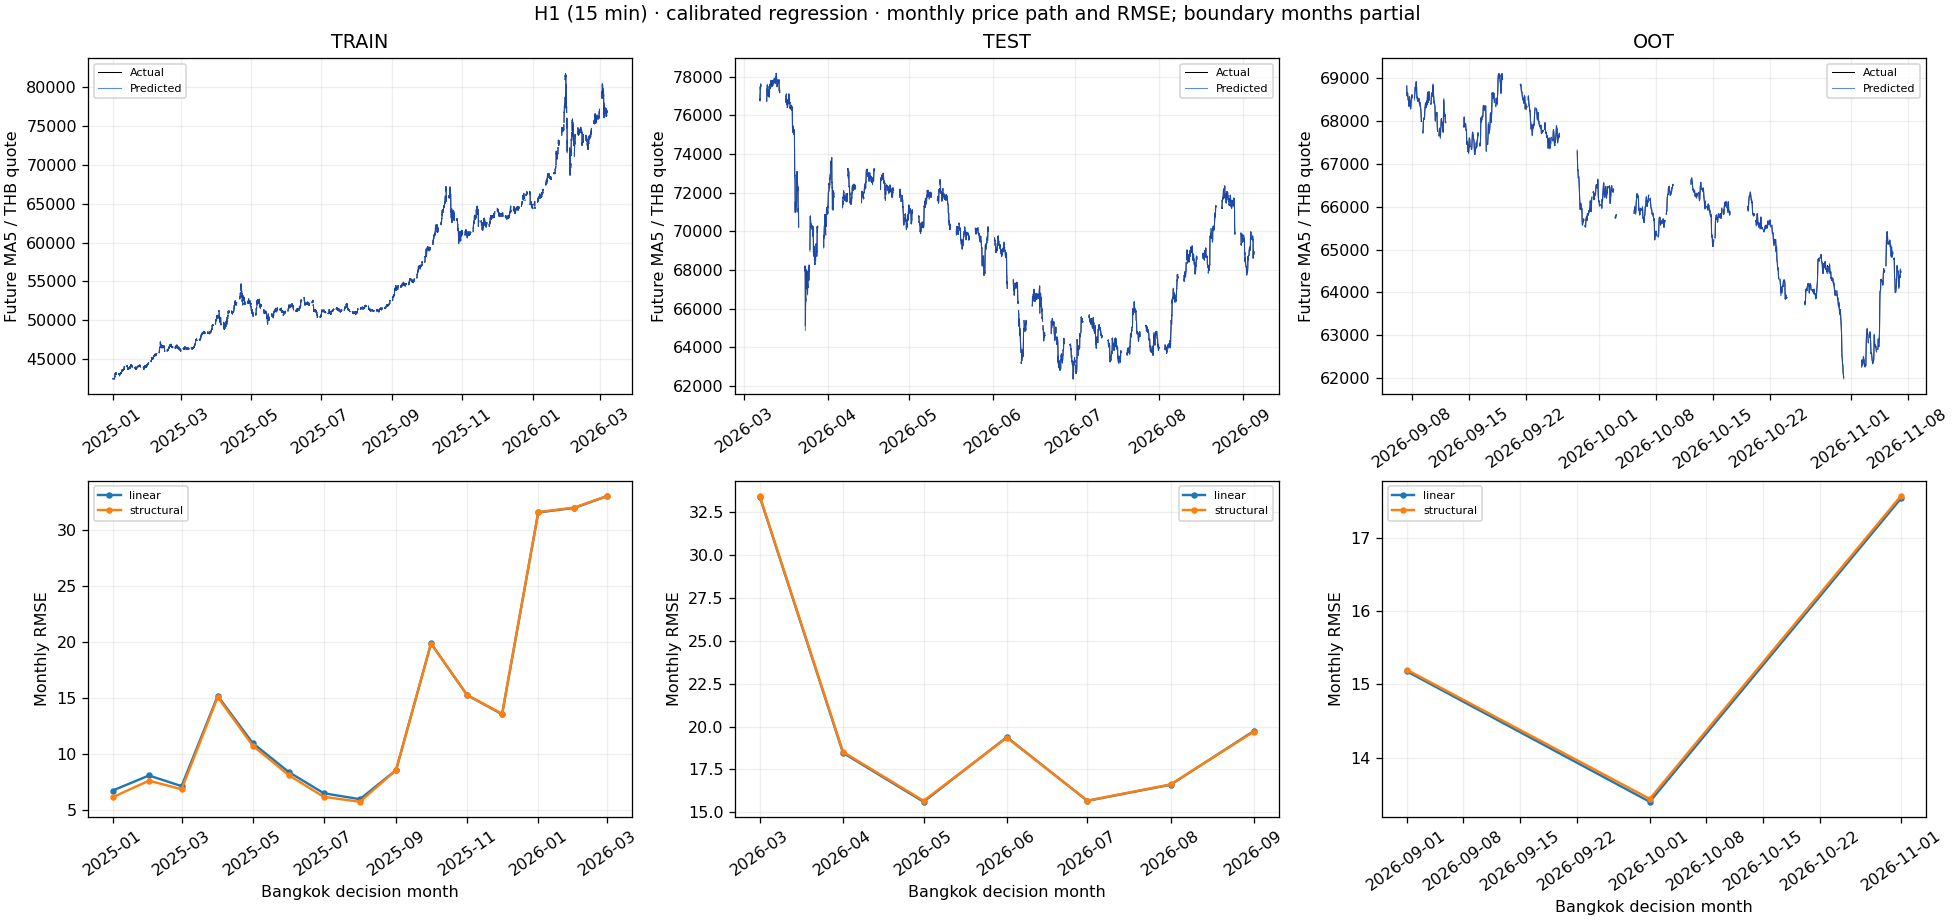

calibrated_classification


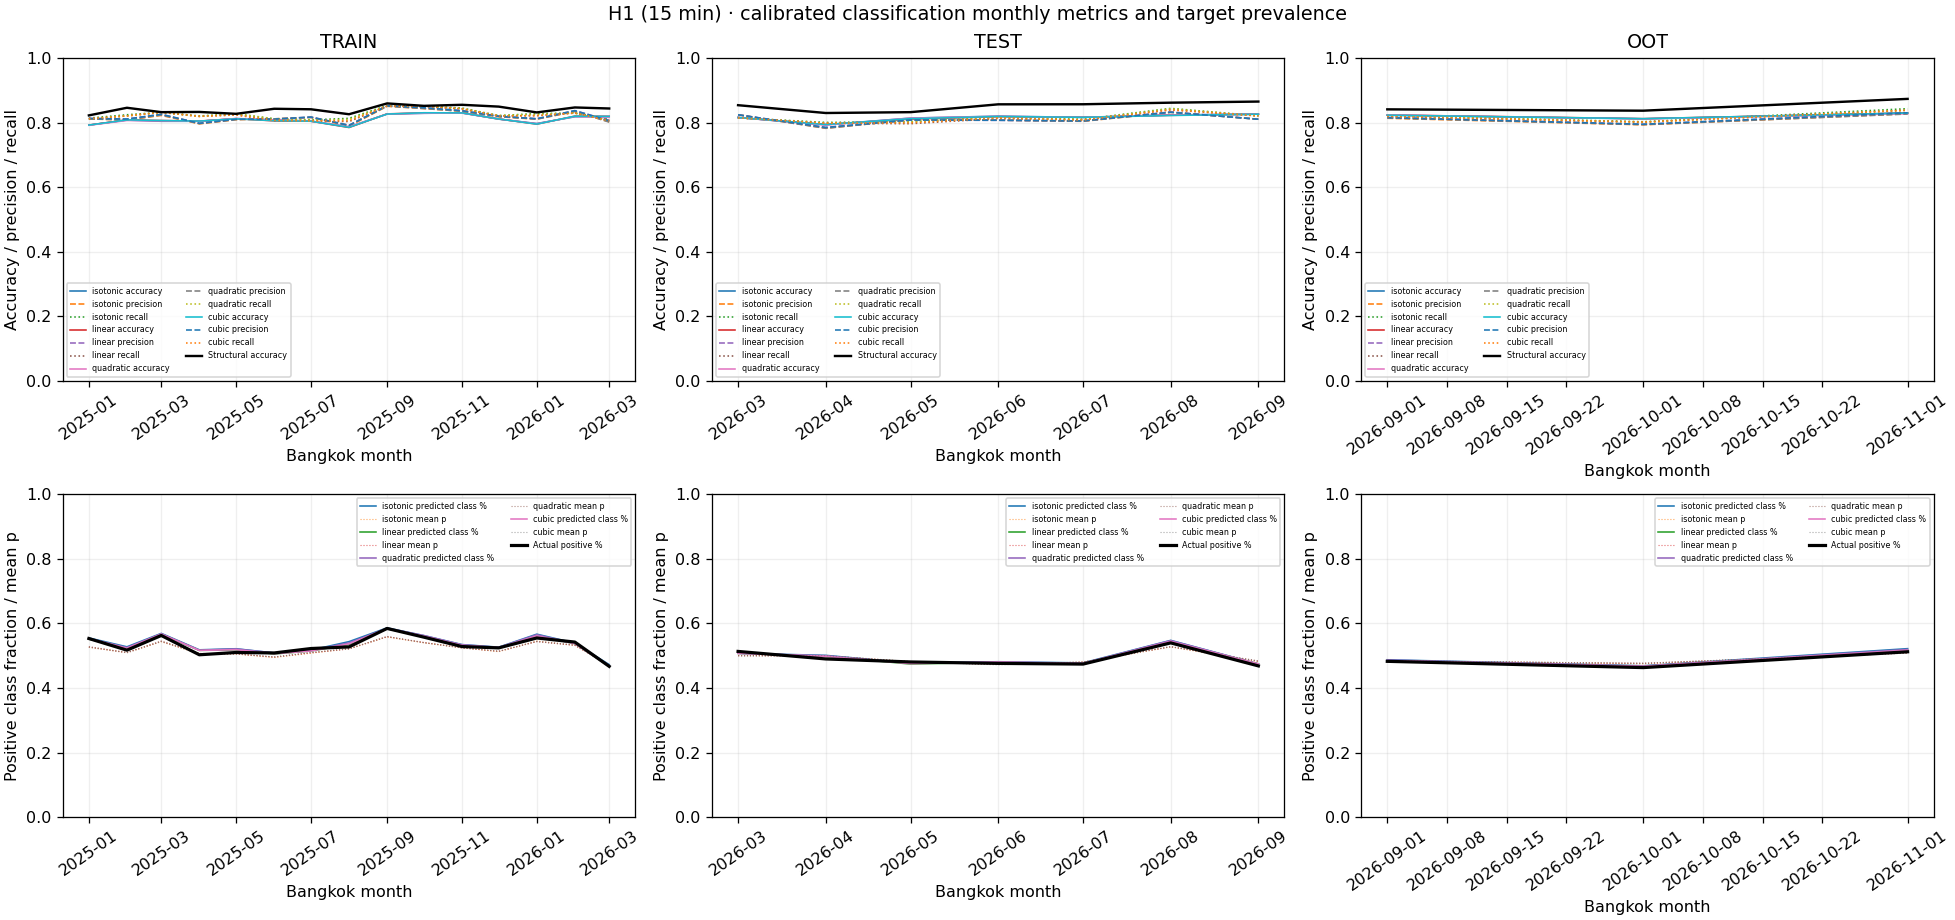

In [5]:
for name in ['raw_regression','raw_classification','calibration','calibrated_regression','calibrated_classification']:
    print(name)
    display(Image(filename=str(P/f'plots/h1_{name}.png')))

## Horizon 2: 30 minutes — Excel 3.5–3.10
Charts cover TRAIN, TEST and OOT. Monthly boundary samples can be partial. Price lines break at market gaps. Classification panels distinguish predicted positive-class share from average predicted probability. Fixed raw-TRAIN probability deciles define ECE across all methods/sets.

raw_regression


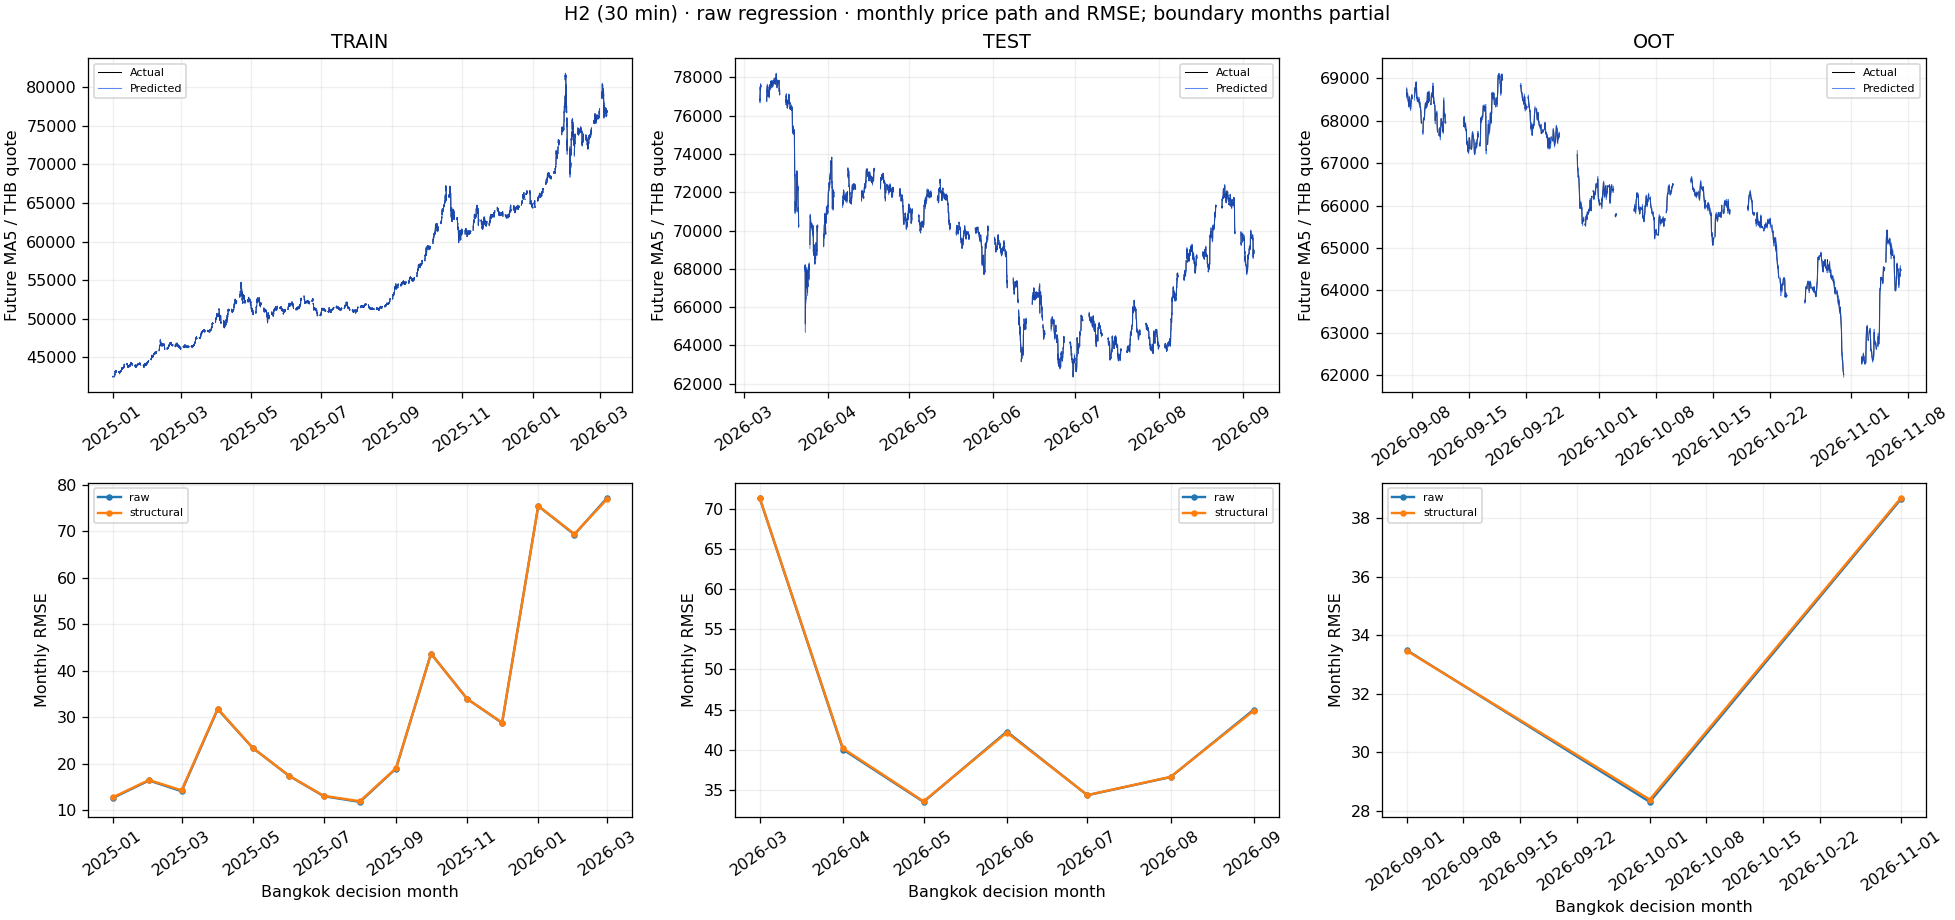

raw_classification


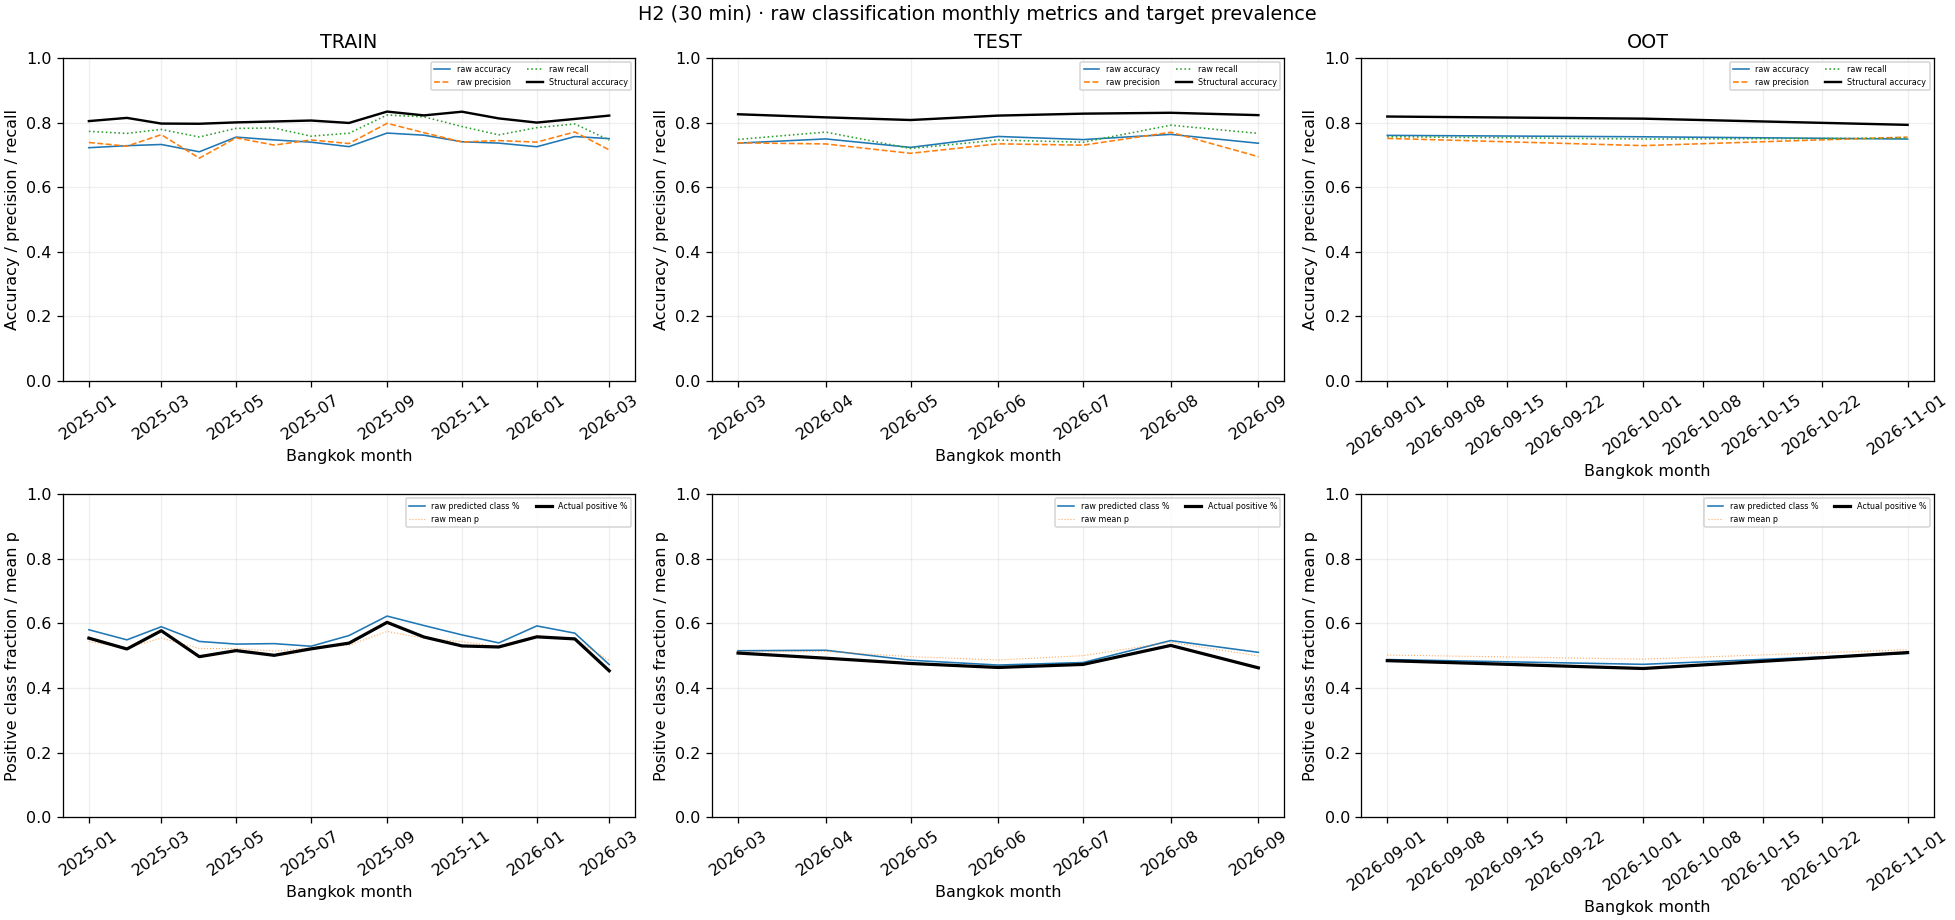

calibration


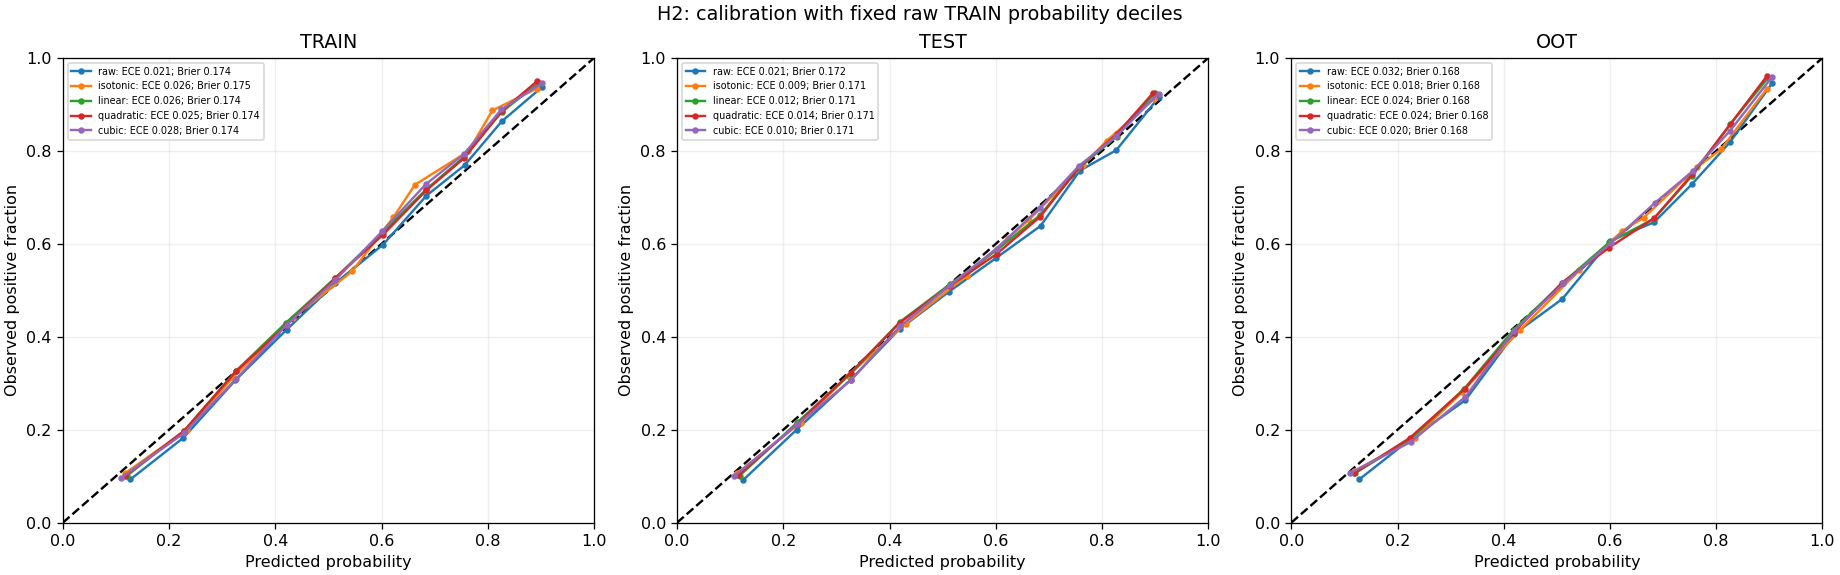

calibrated_regression


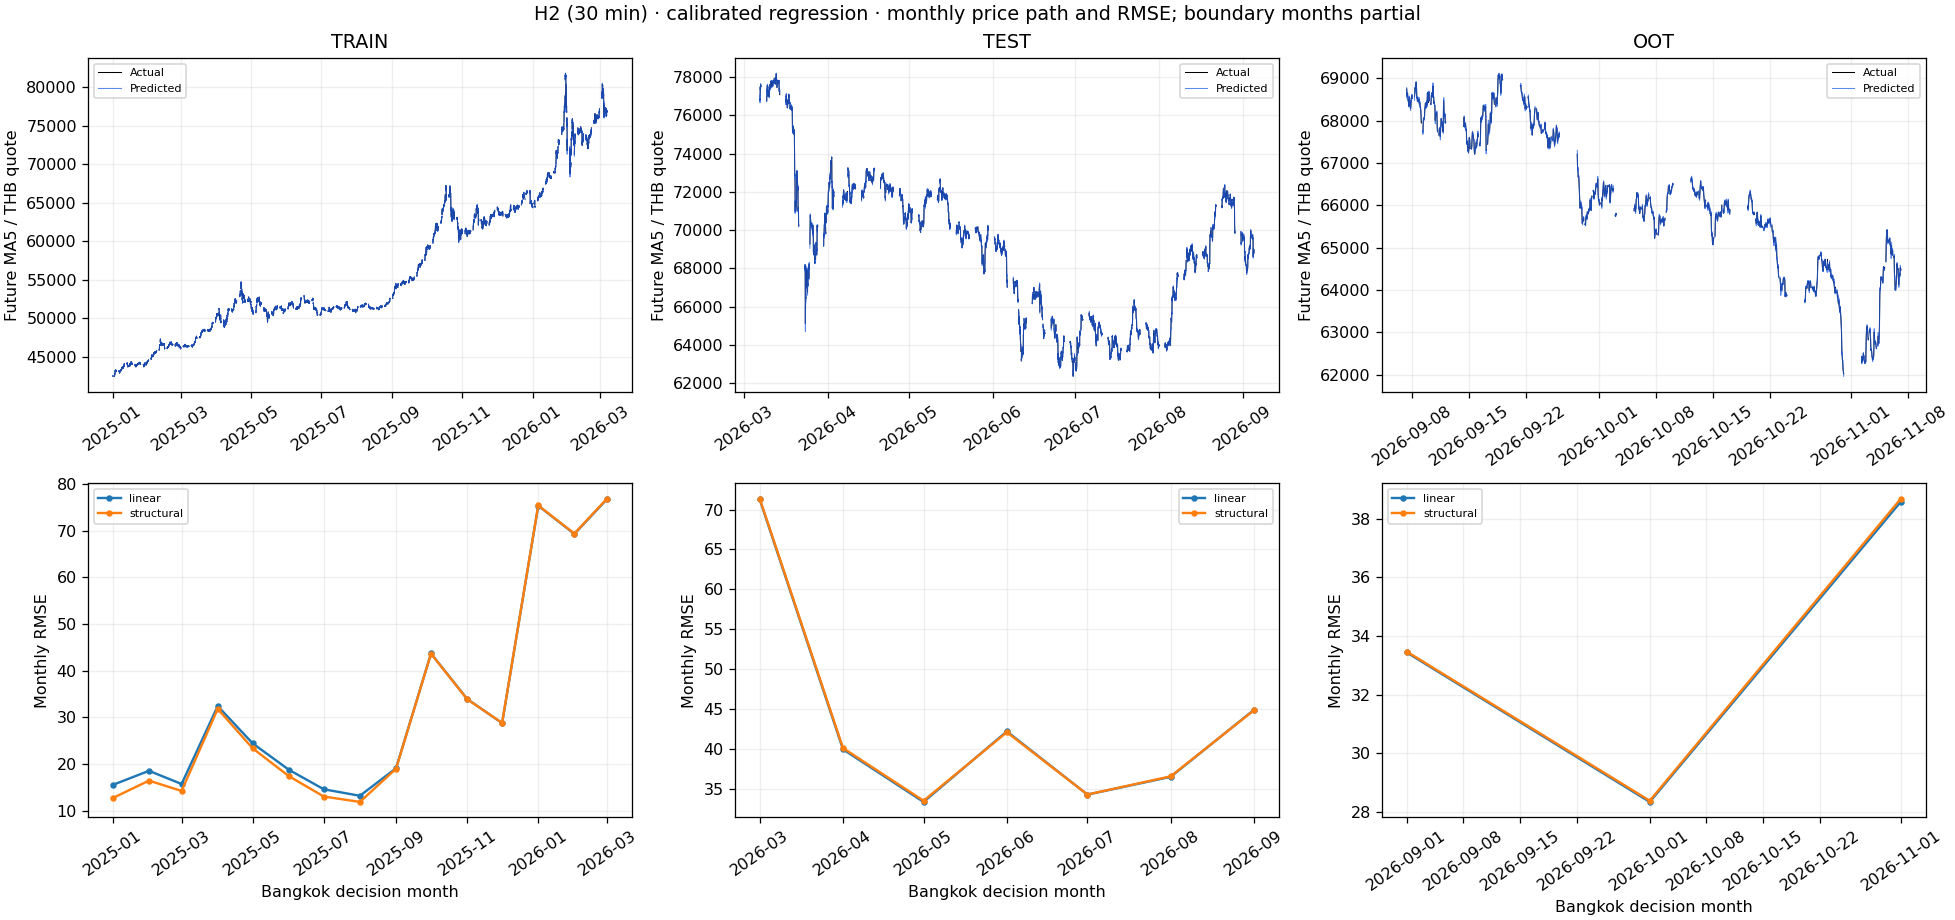

calibrated_classification


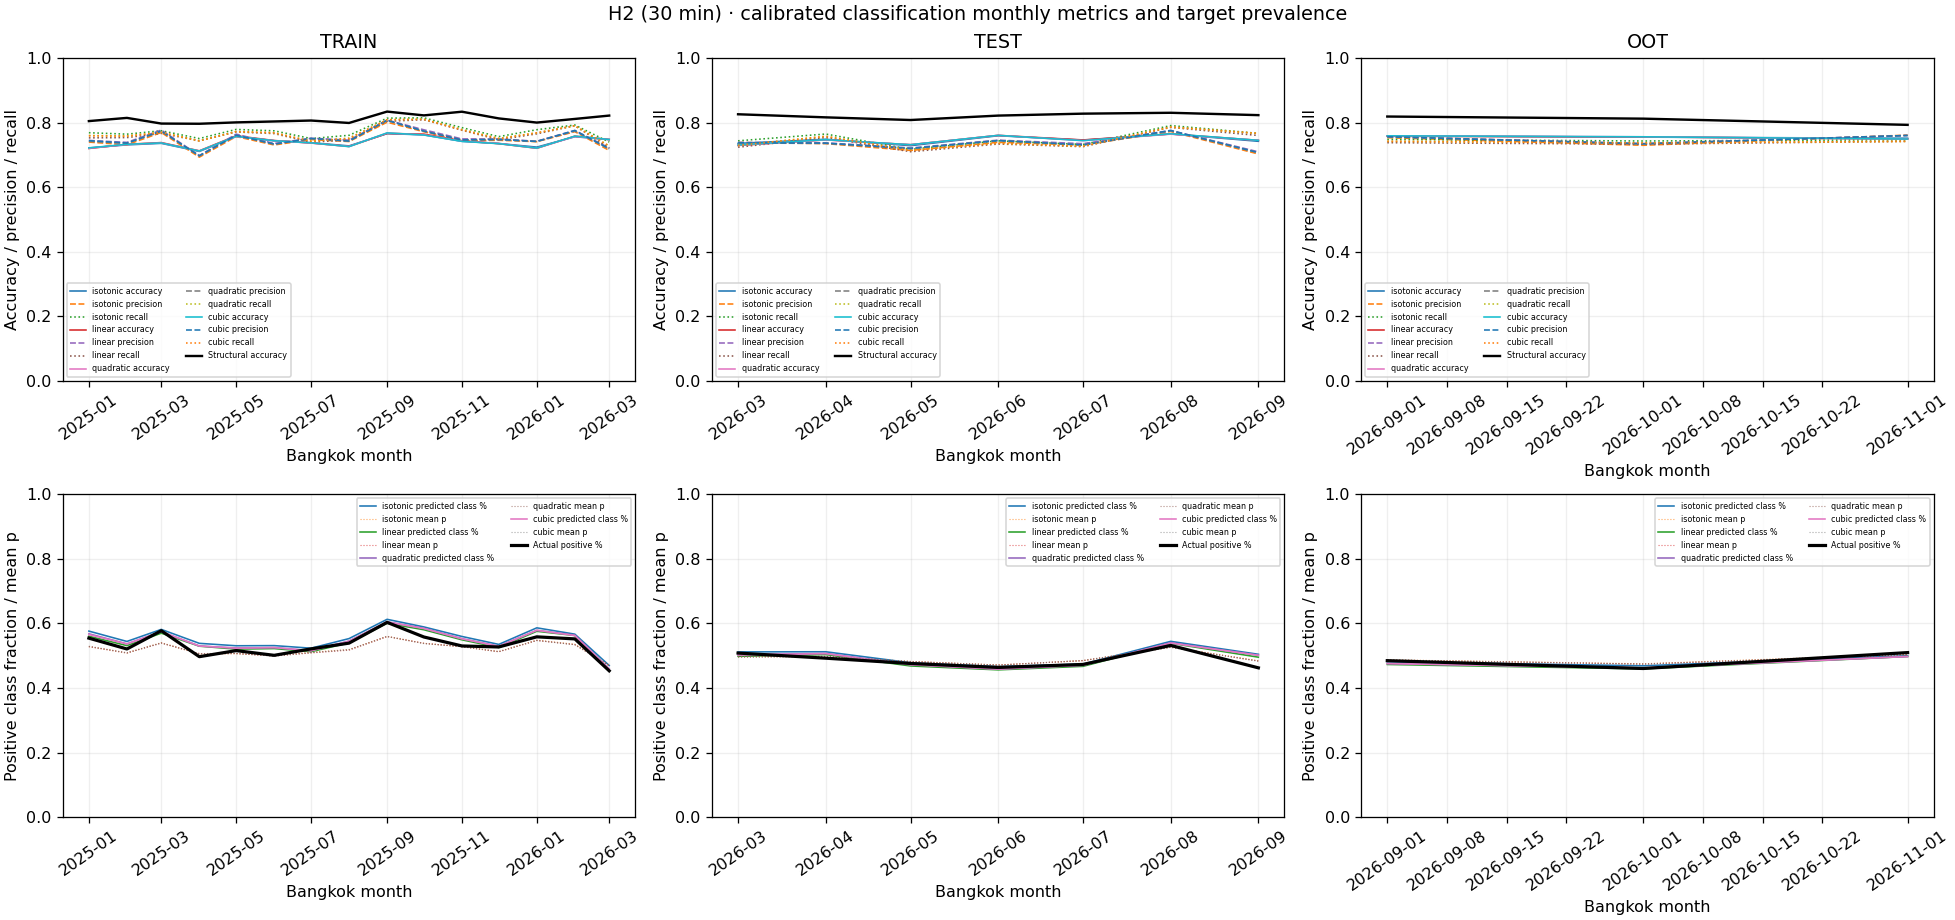

In [6]:
for name in ['raw_regression','raw_classification','calibration','calibrated_regression','calibrated_classification']:
    print(name)
    display(Image(filename=str(P/f'plots/h2_{name}.png')))

## Horizon 3: 45 minutes — Excel 3.5–3.10
Charts cover TRAIN, TEST and OOT. Monthly boundary samples can be partial. Price lines break at market gaps. Classification panels distinguish predicted positive-class share from average predicted probability. Fixed raw-TRAIN probability deciles define ECE across all methods/sets.

raw_regression


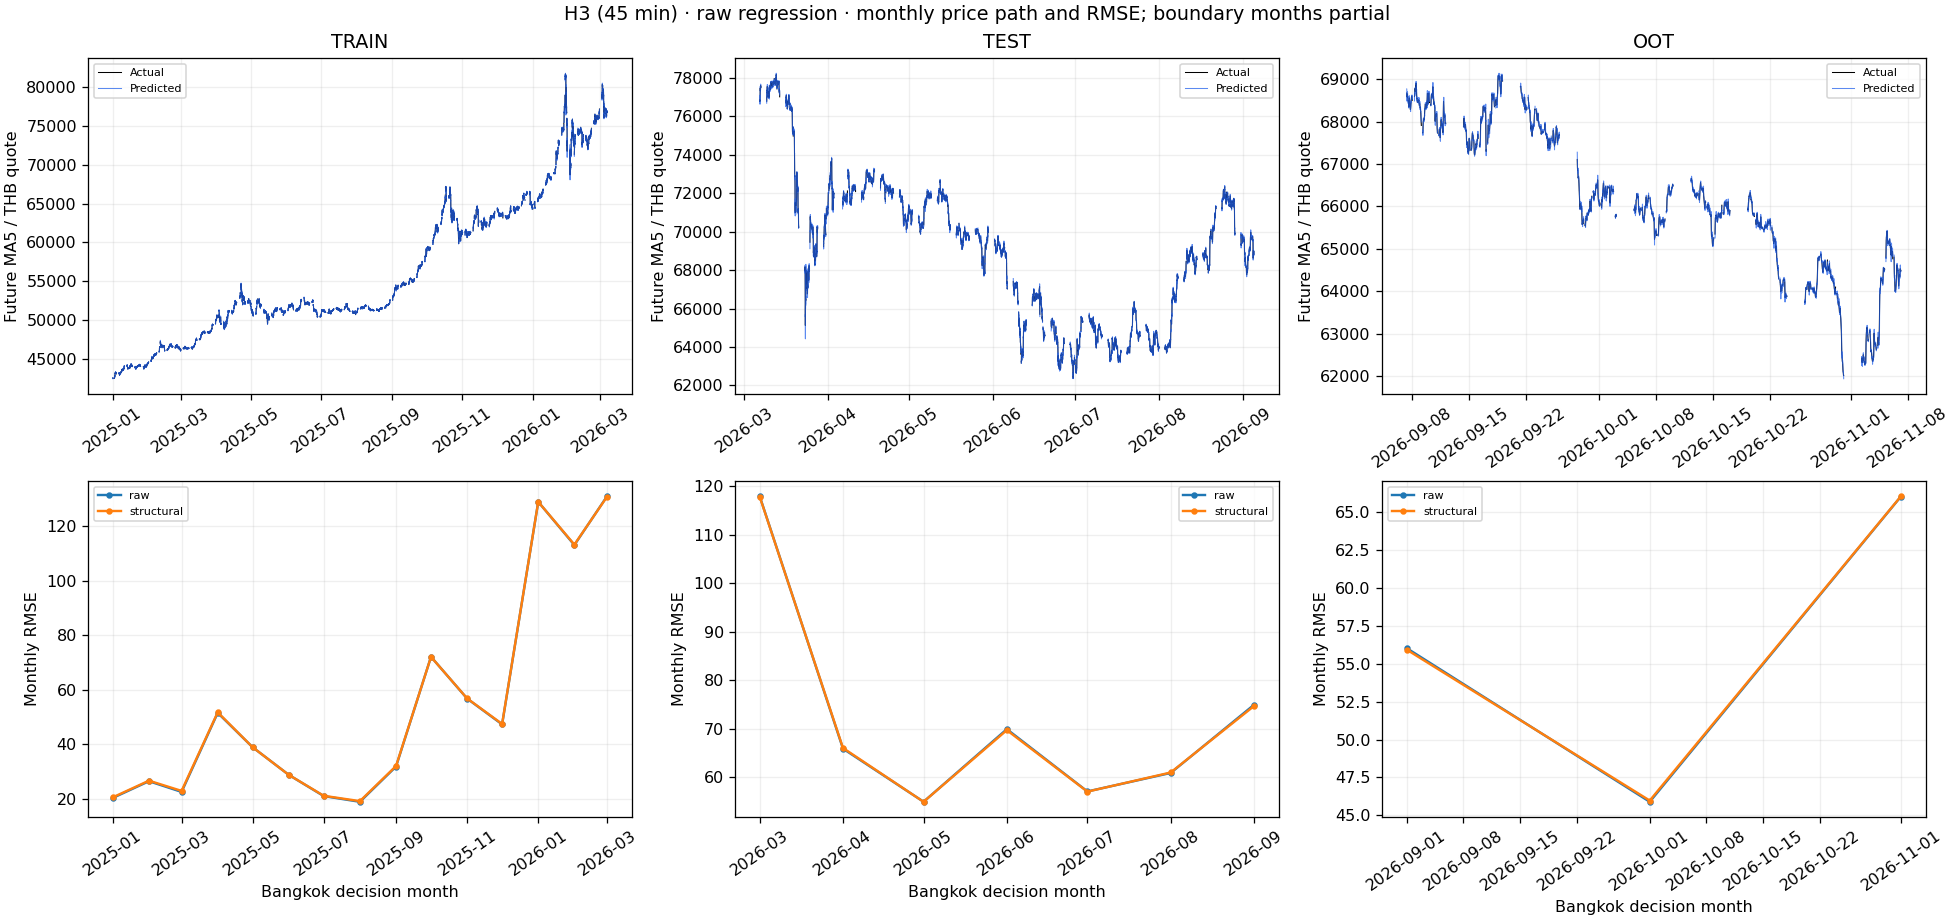

raw_classification


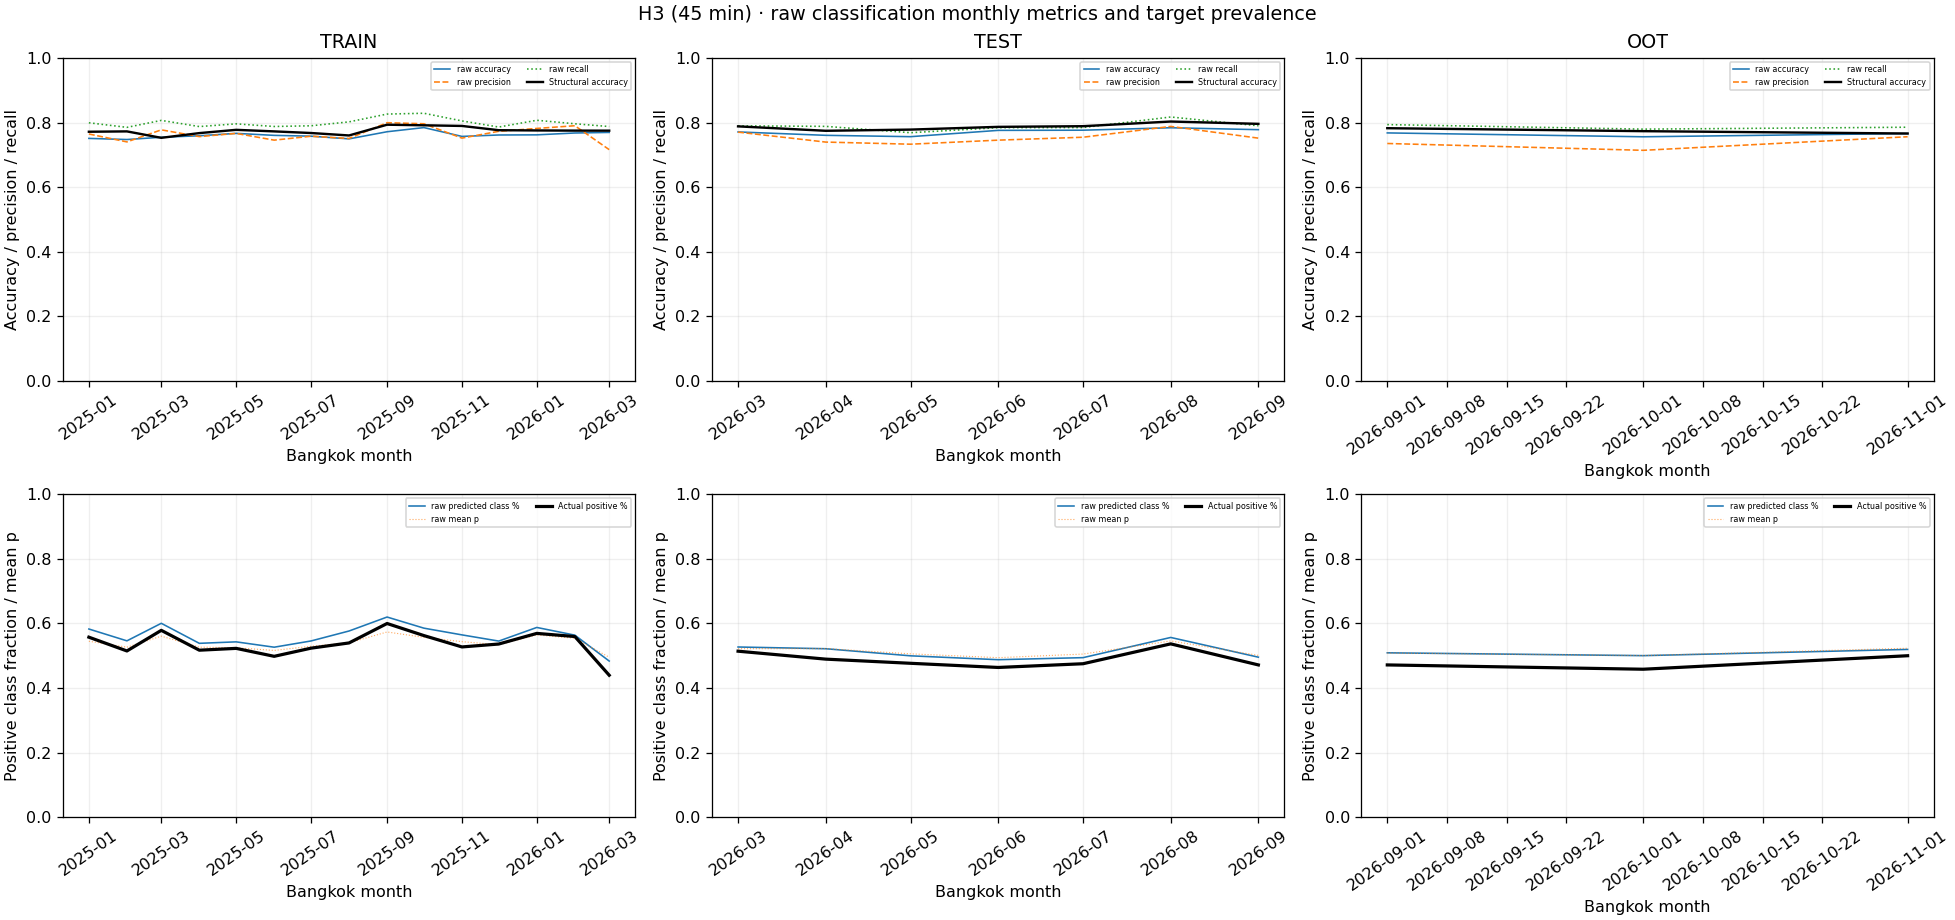

calibration


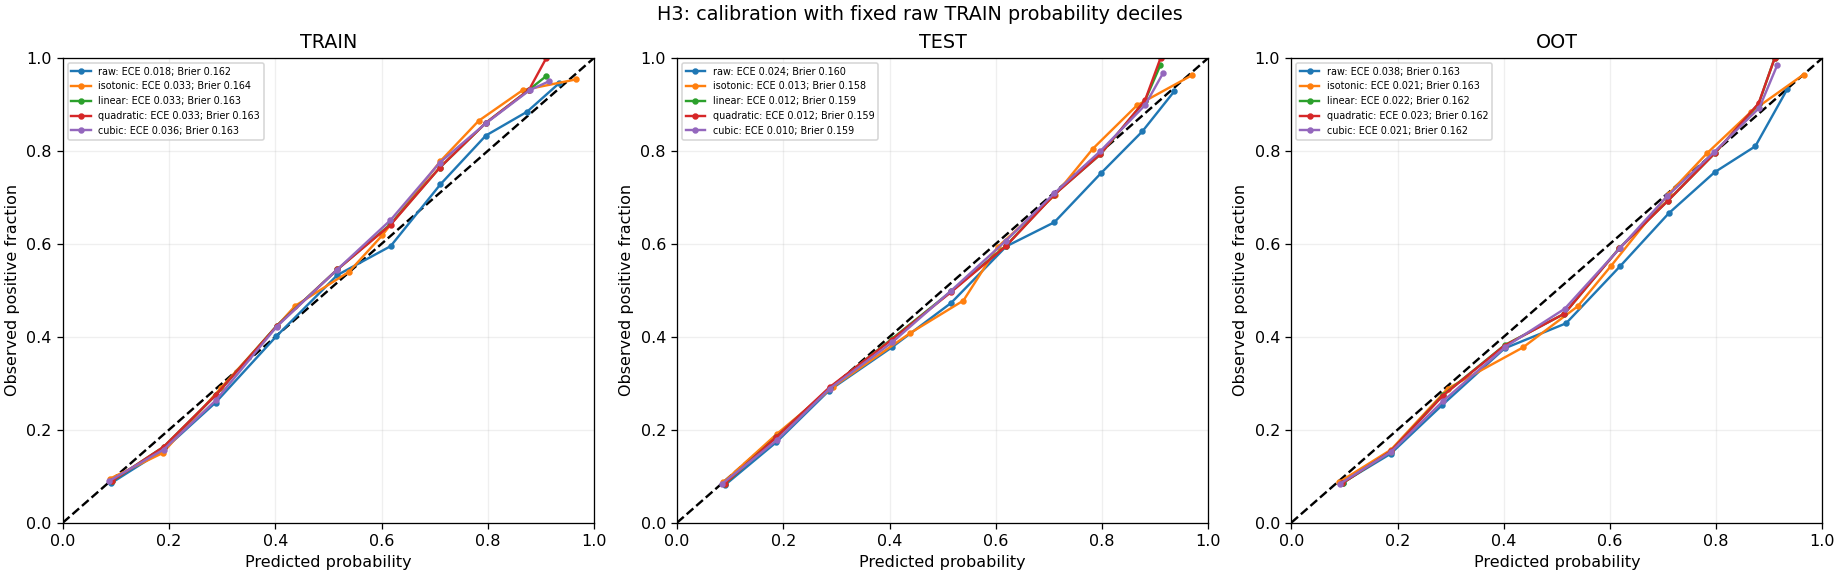

calibrated_regression


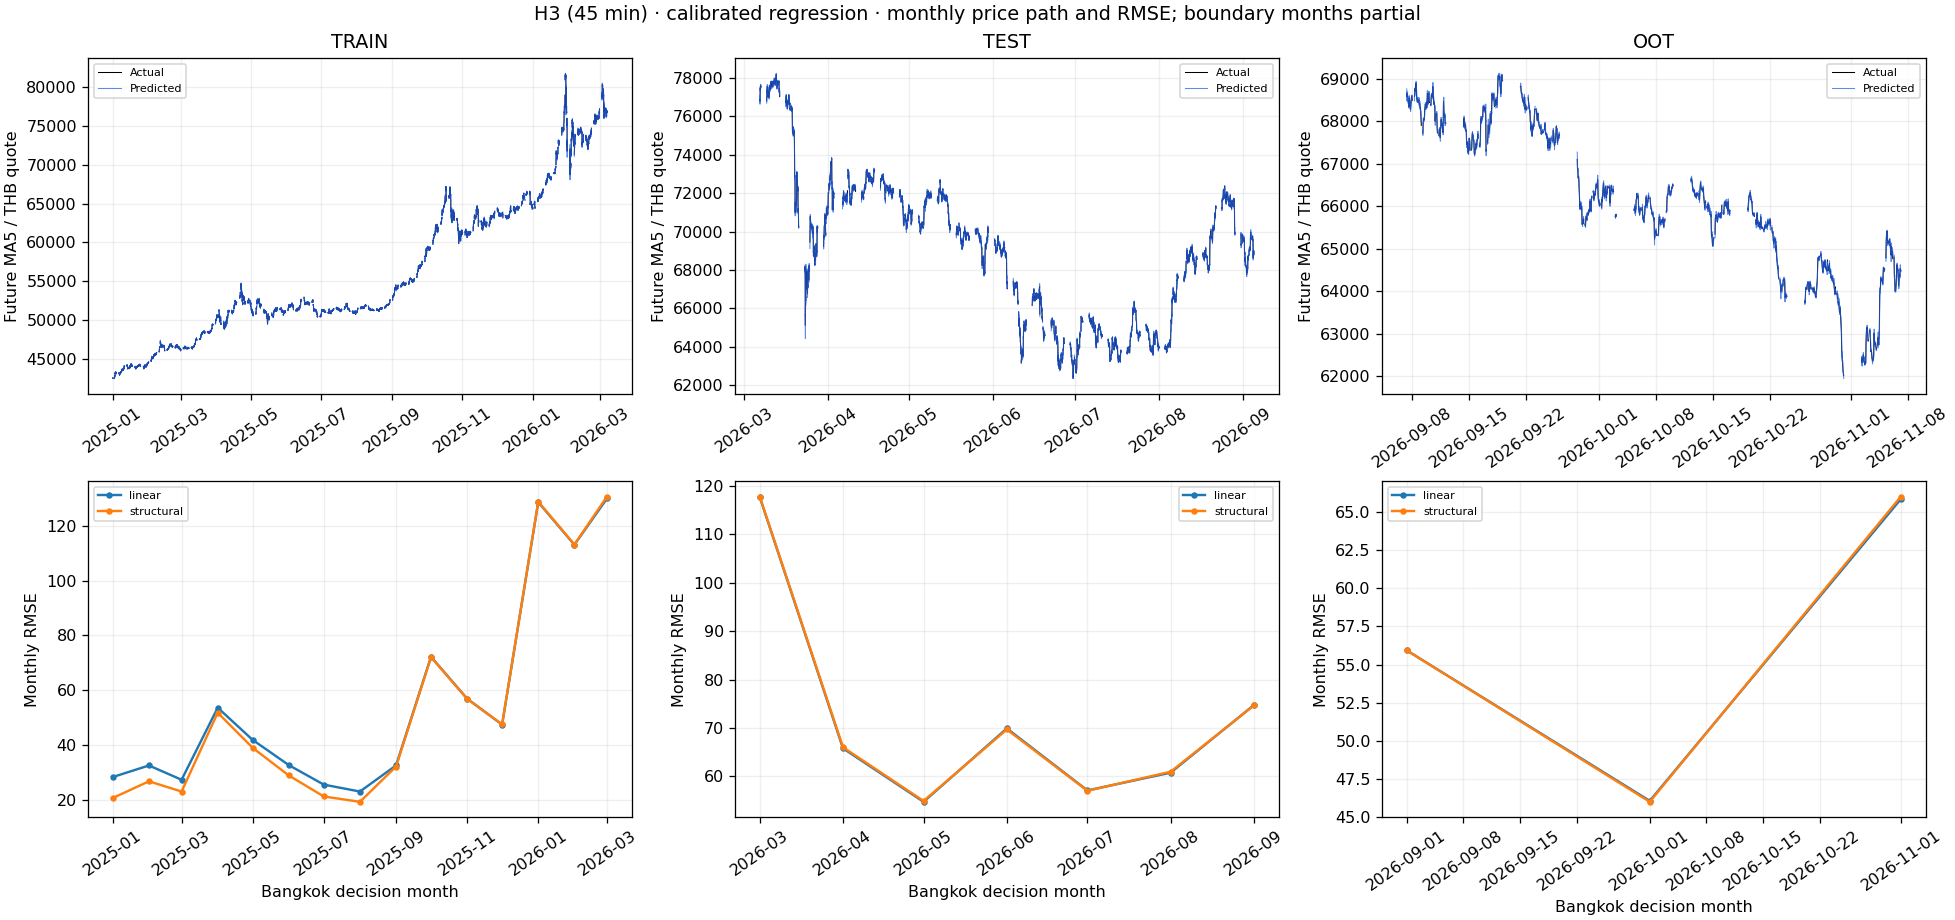

calibrated_classification


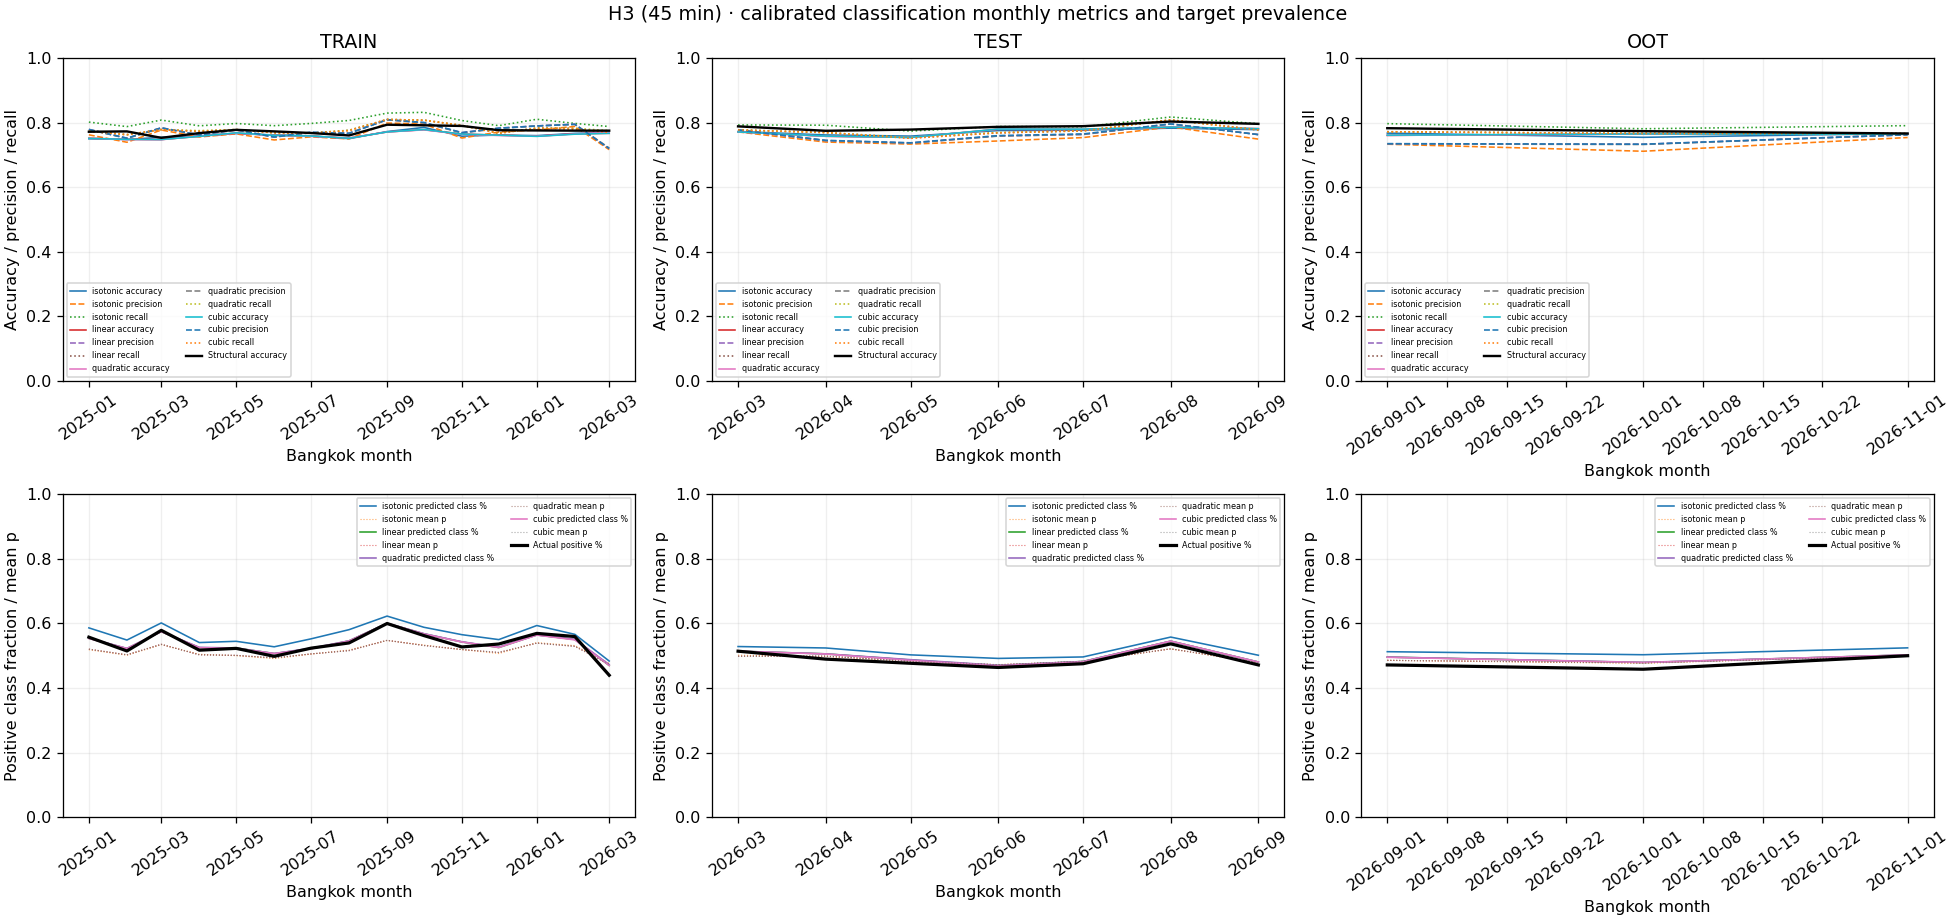

In [7]:
for name in ['raw_regression','raw_classification','calibration','calibrated_regression','calibrated_classification']:
    print(name)
    display(Image(filename=str(P/f'plots/h3_{name}.png')))

## Horizon 4: 60 minutes — Excel 3.5–3.10
Charts cover TRAIN, TEST and OOT. Monthly boundary samples can be partial. Price lines break at market gaps. Classification panels distinguish predicted positive-class share from average predicted probability. Fixed raw-TRAIN probability deciles define ECE across all methods/sets.

raw_regression


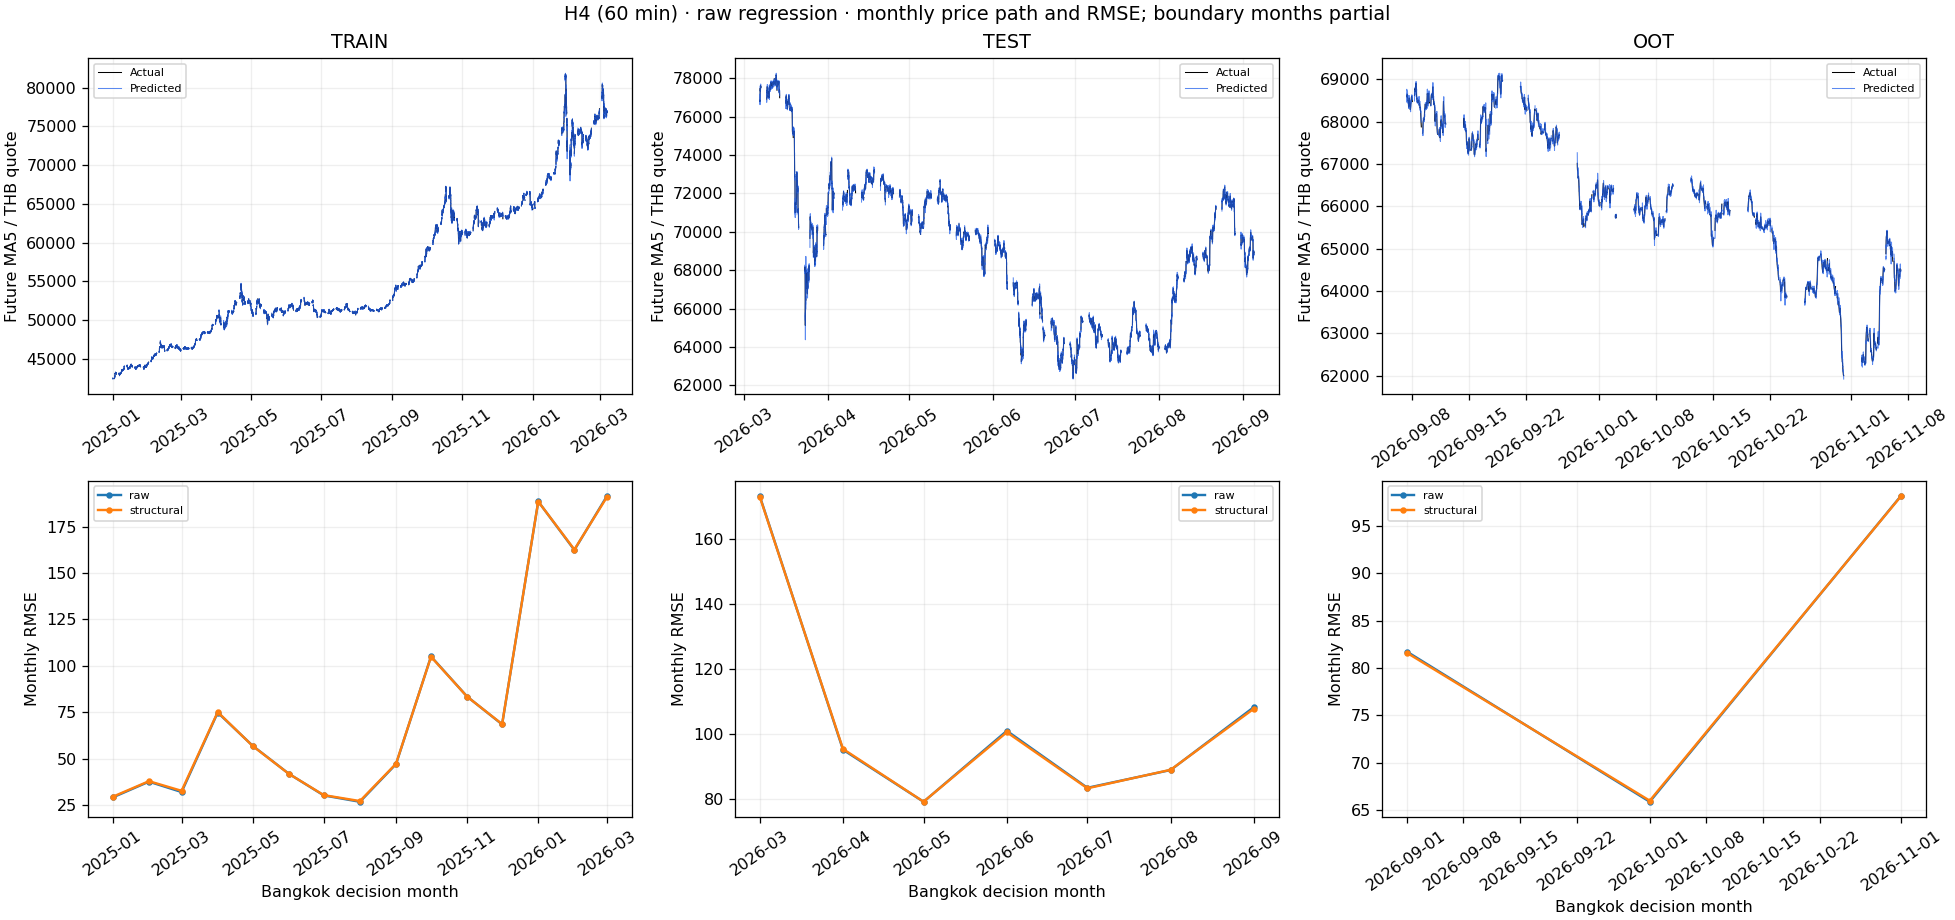

raw_classification


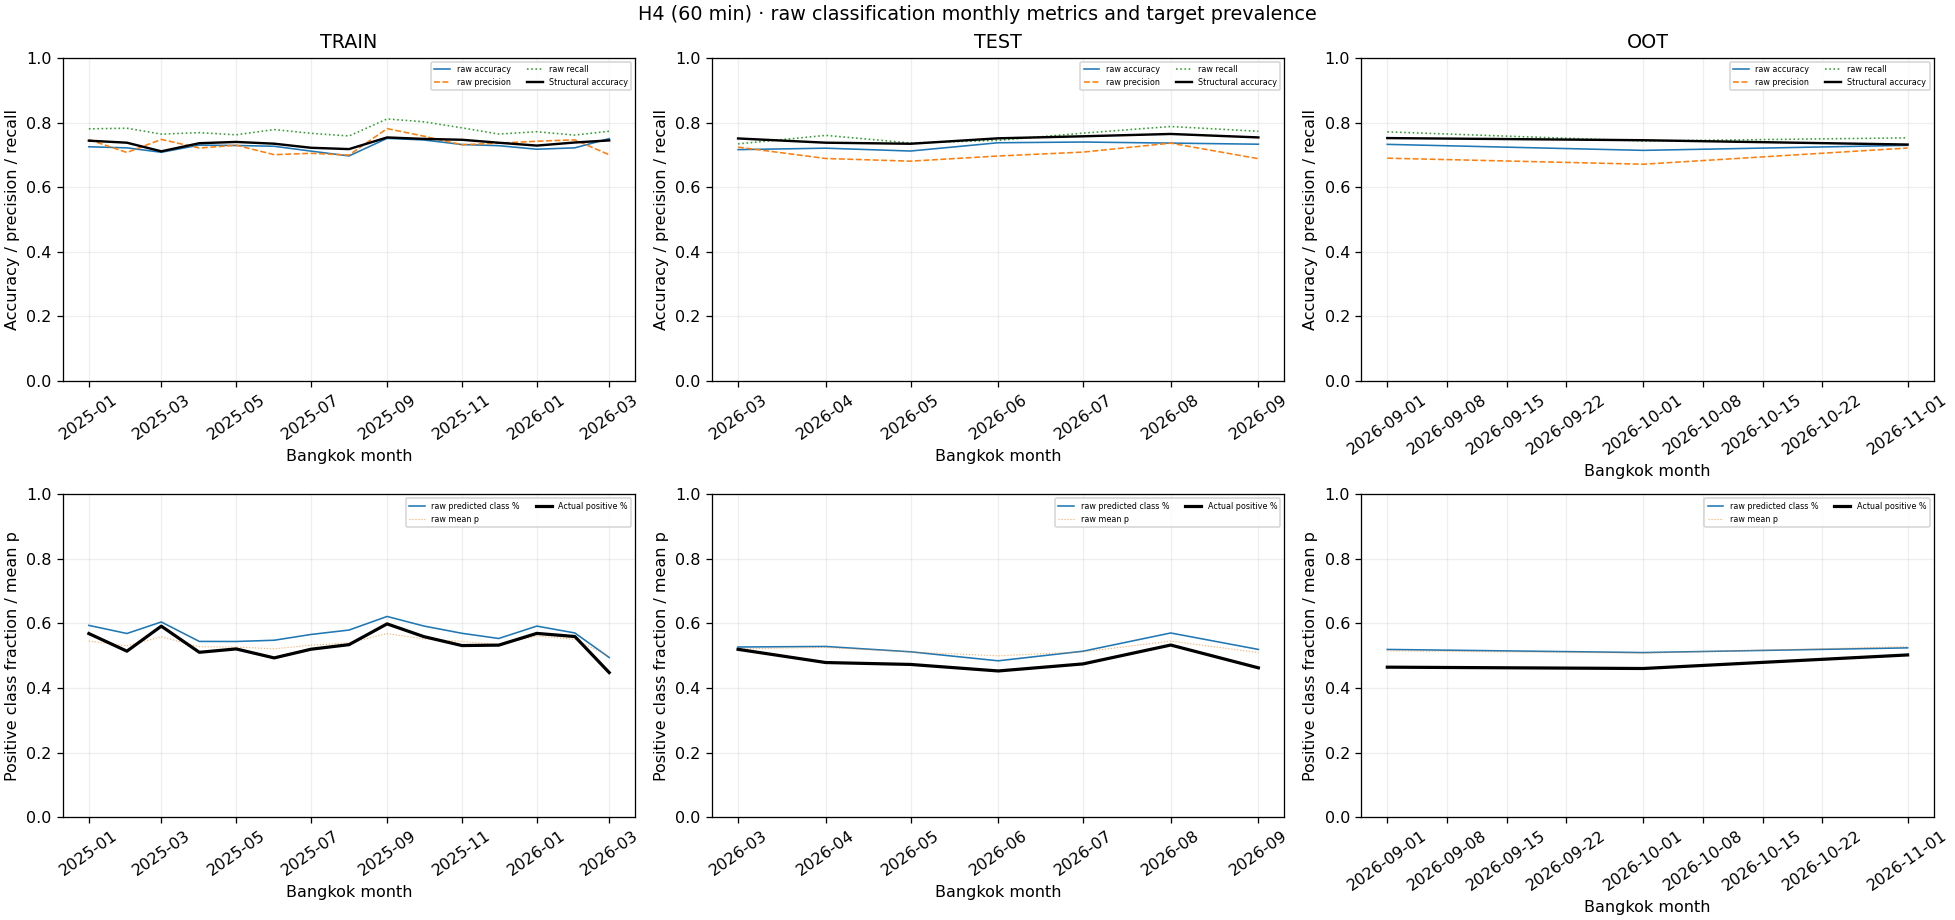

calibration


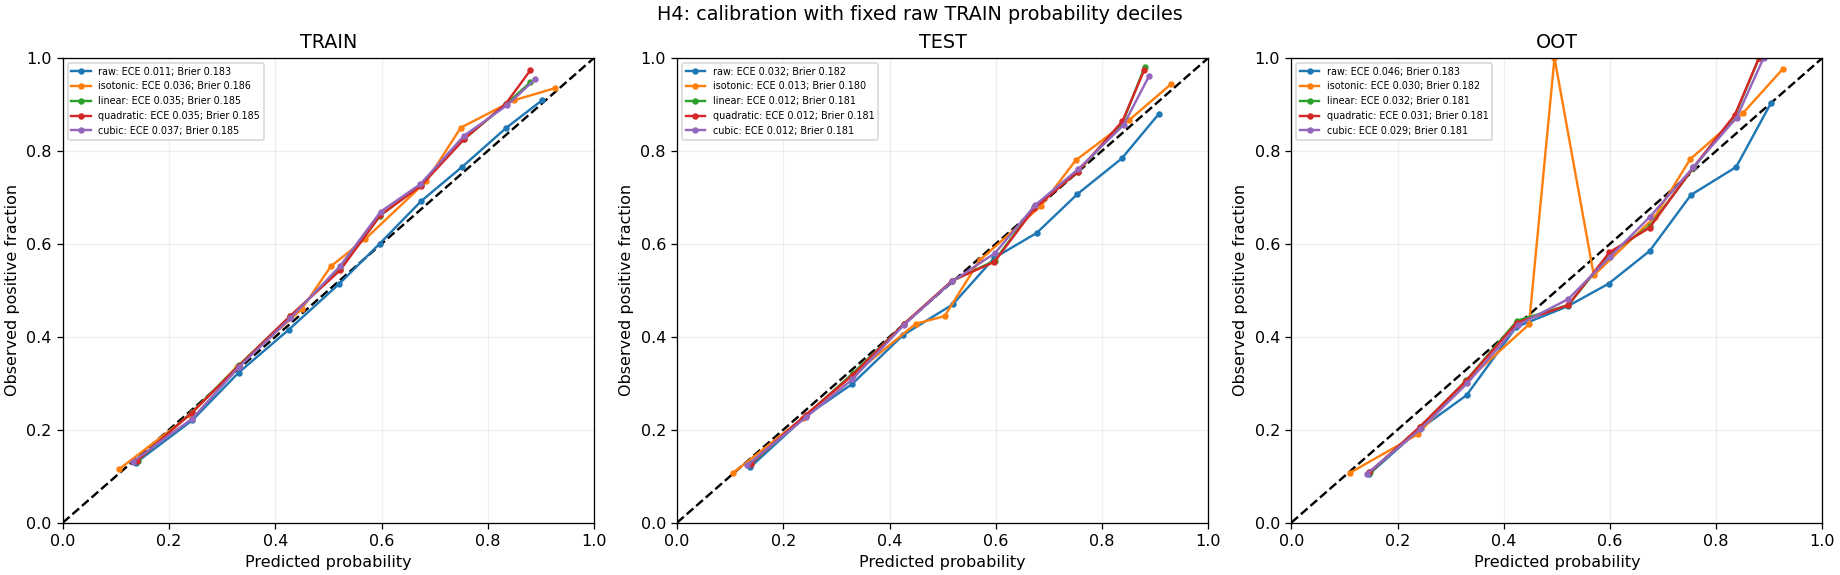

calibrated_regression


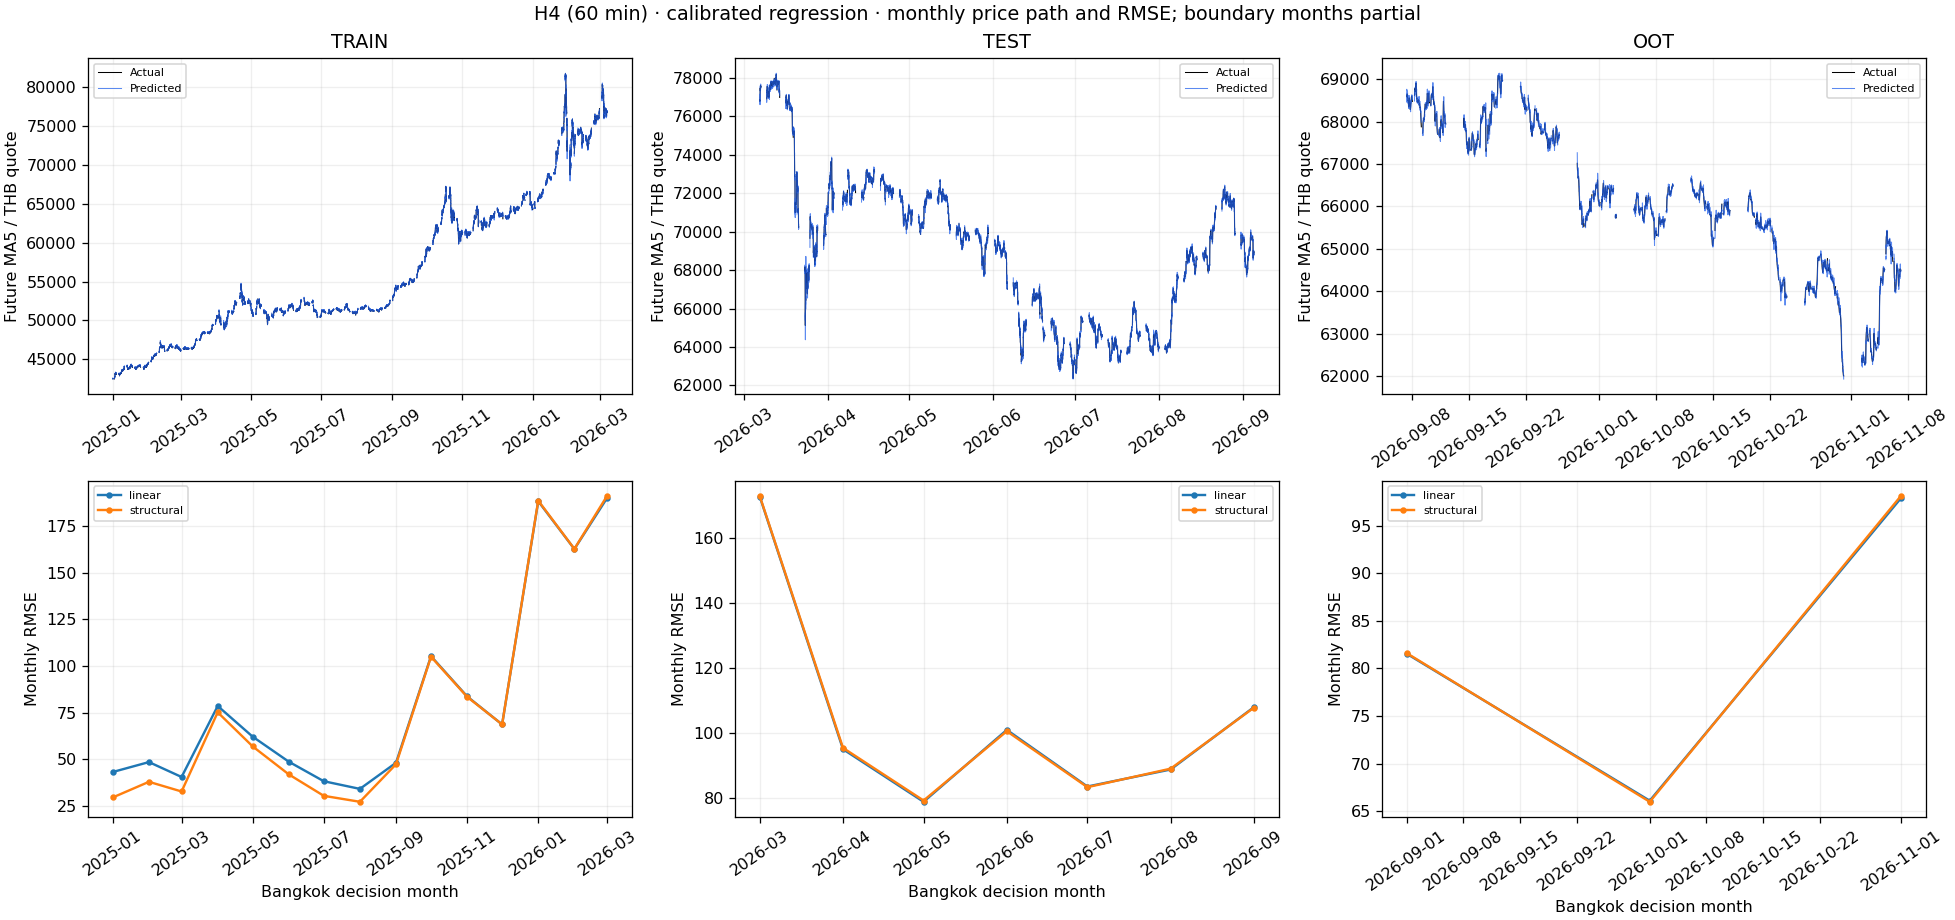

calibrated_classification


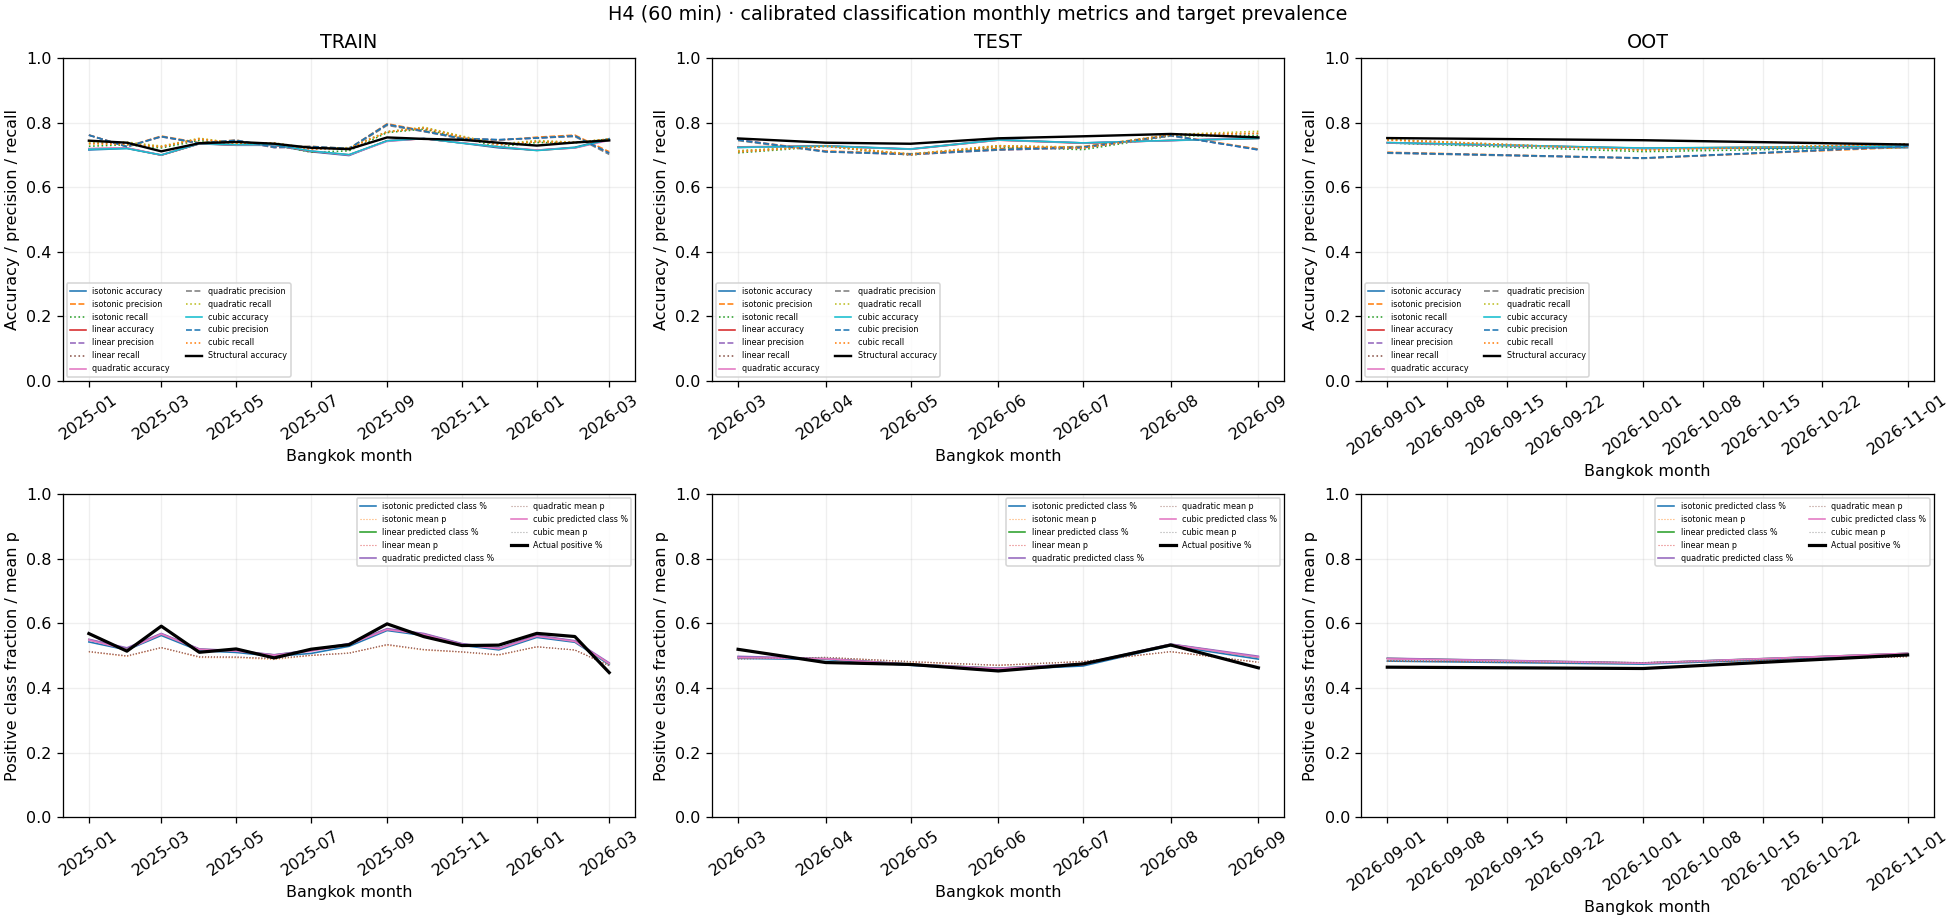

In [8]:
for name in ['raw_regression','raw_classification','calibration','calibrated_regression','calibrated_classification']:
    print(name)
    display(Image(filename=str(P/f'plots/h4_{name}.png')))

## Horizon 5: 75 minutes — Excel 3.5–3.10
Charts cover TRAIN, TEST and OOT. Monthly boundary samples can be partial. Price lines break at market gaps. Classification panels distinguish predicted positive-class share from average predicted probability. Fixed raw-TRAIN probability deciles define ECE across all methods/sets.

raw_regression


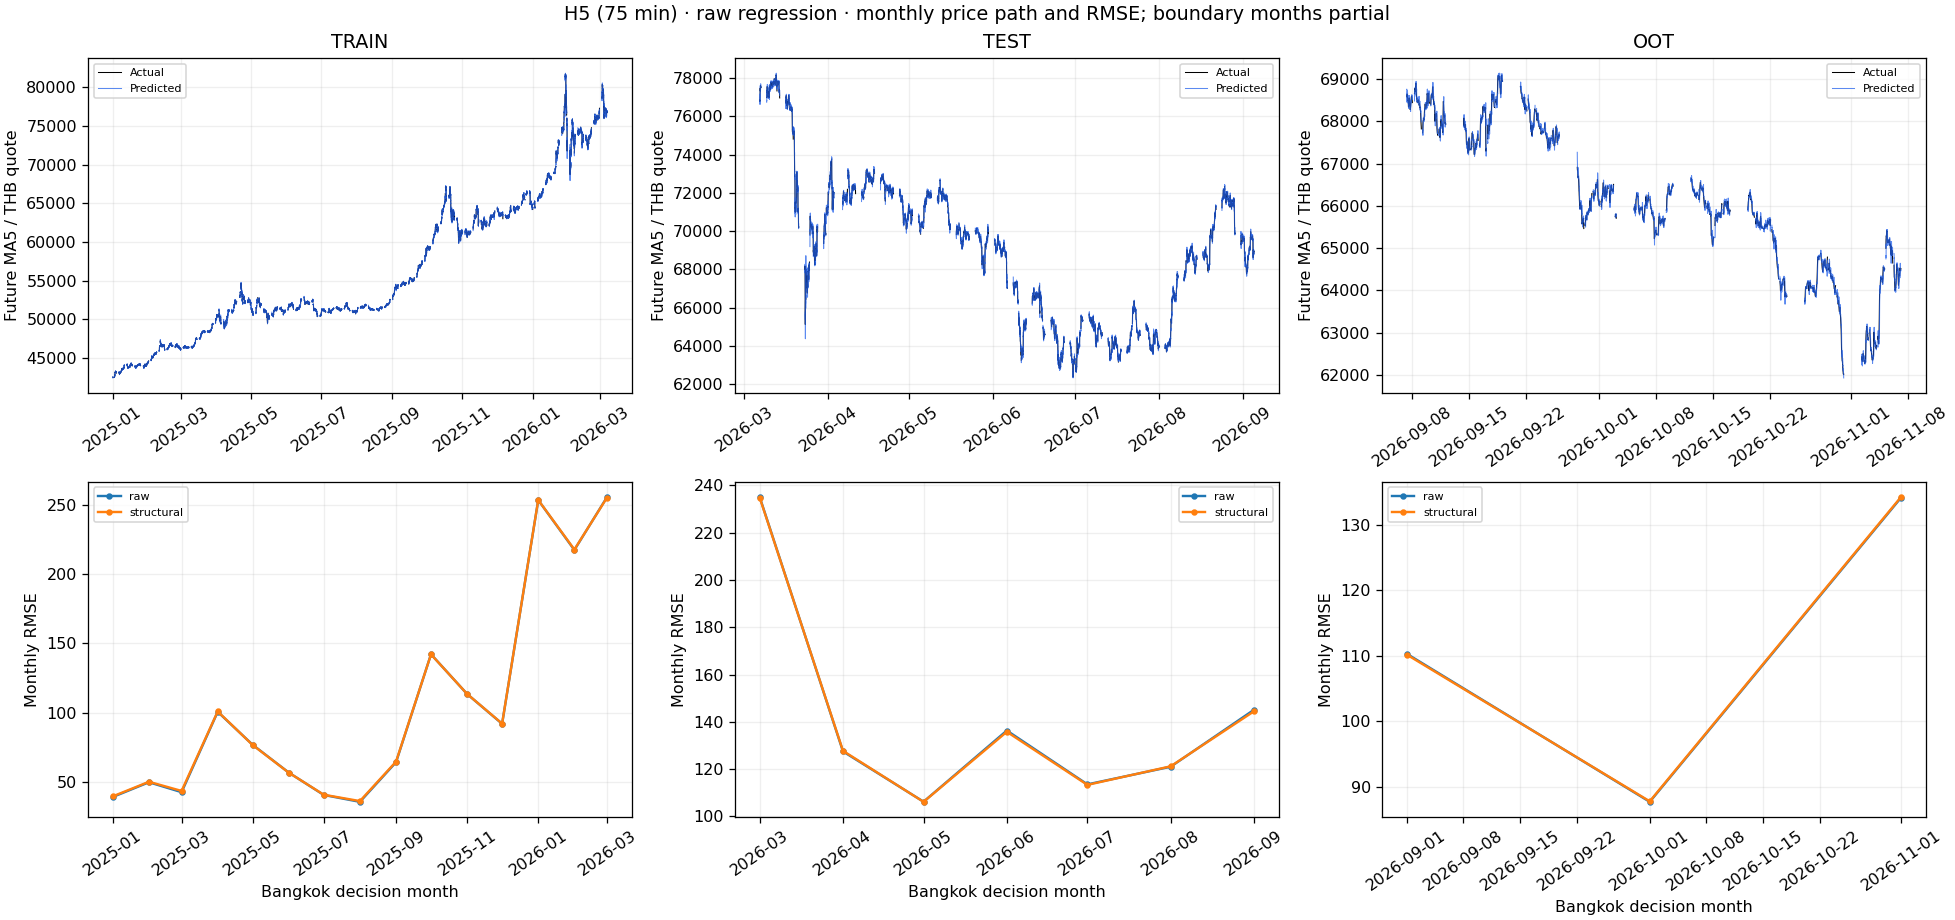

raw_classification


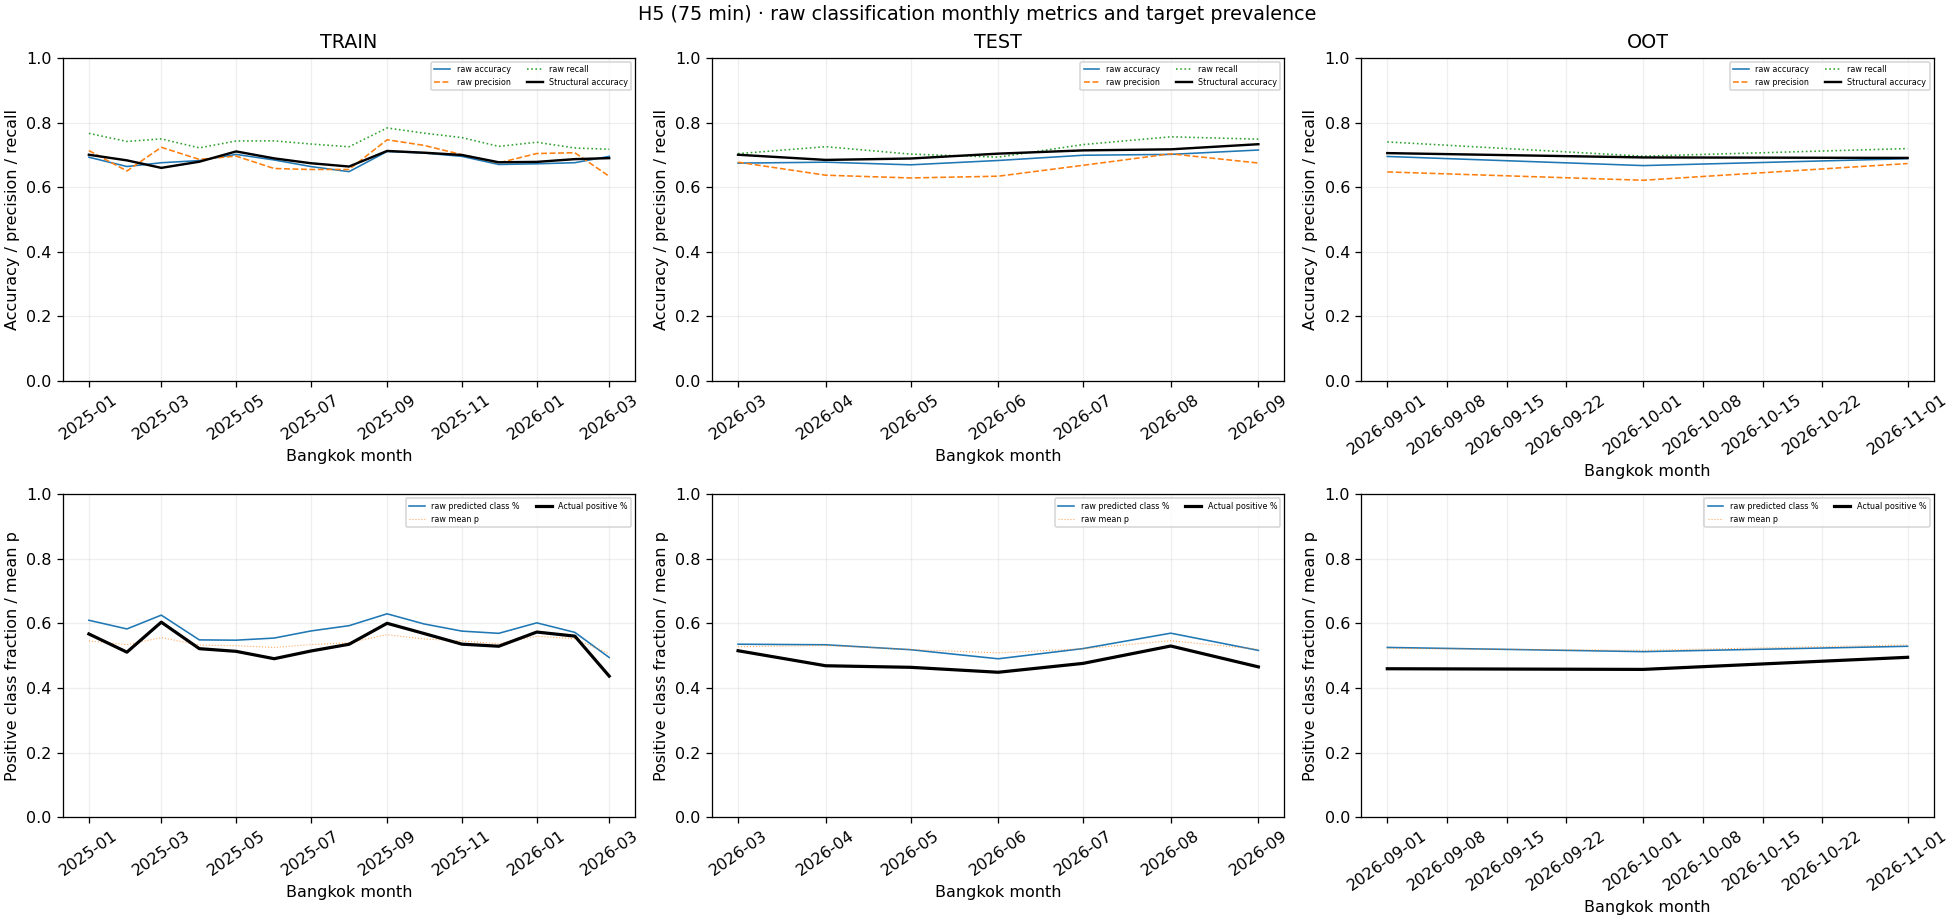

calibration


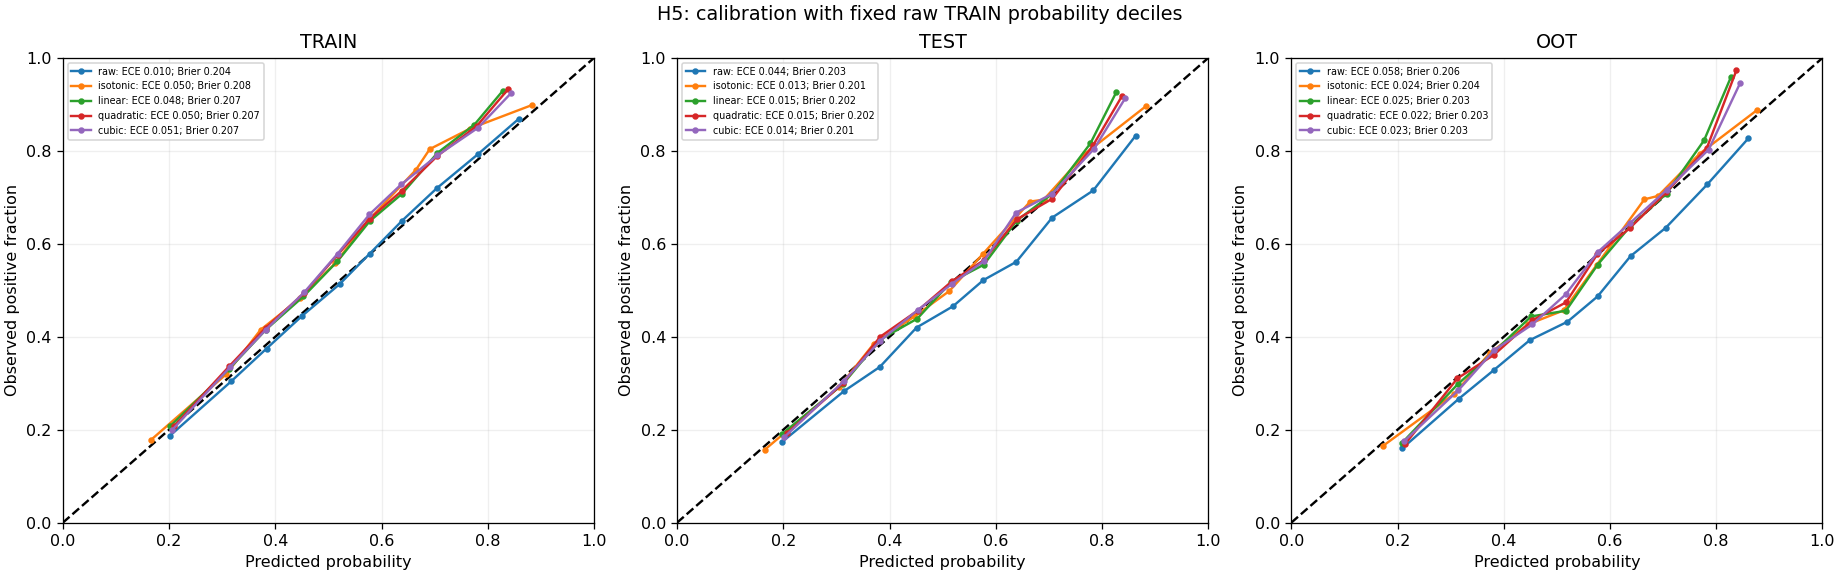

calibrated_regression


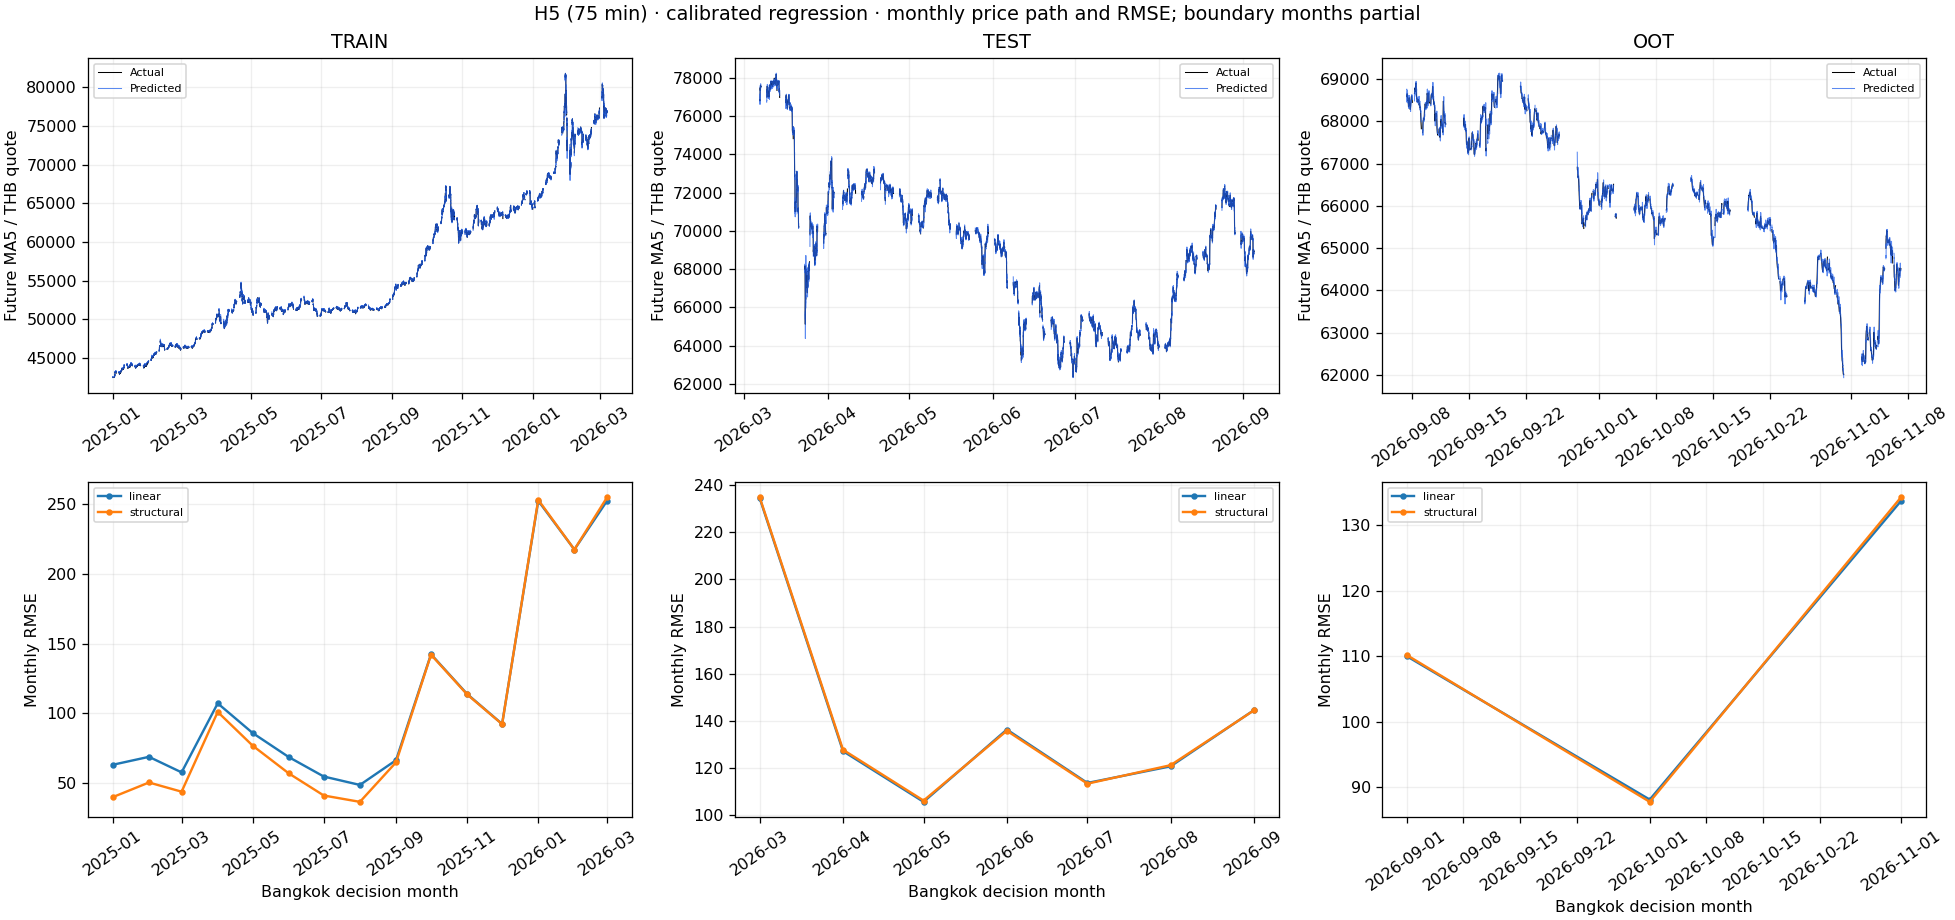

calibrated_classification


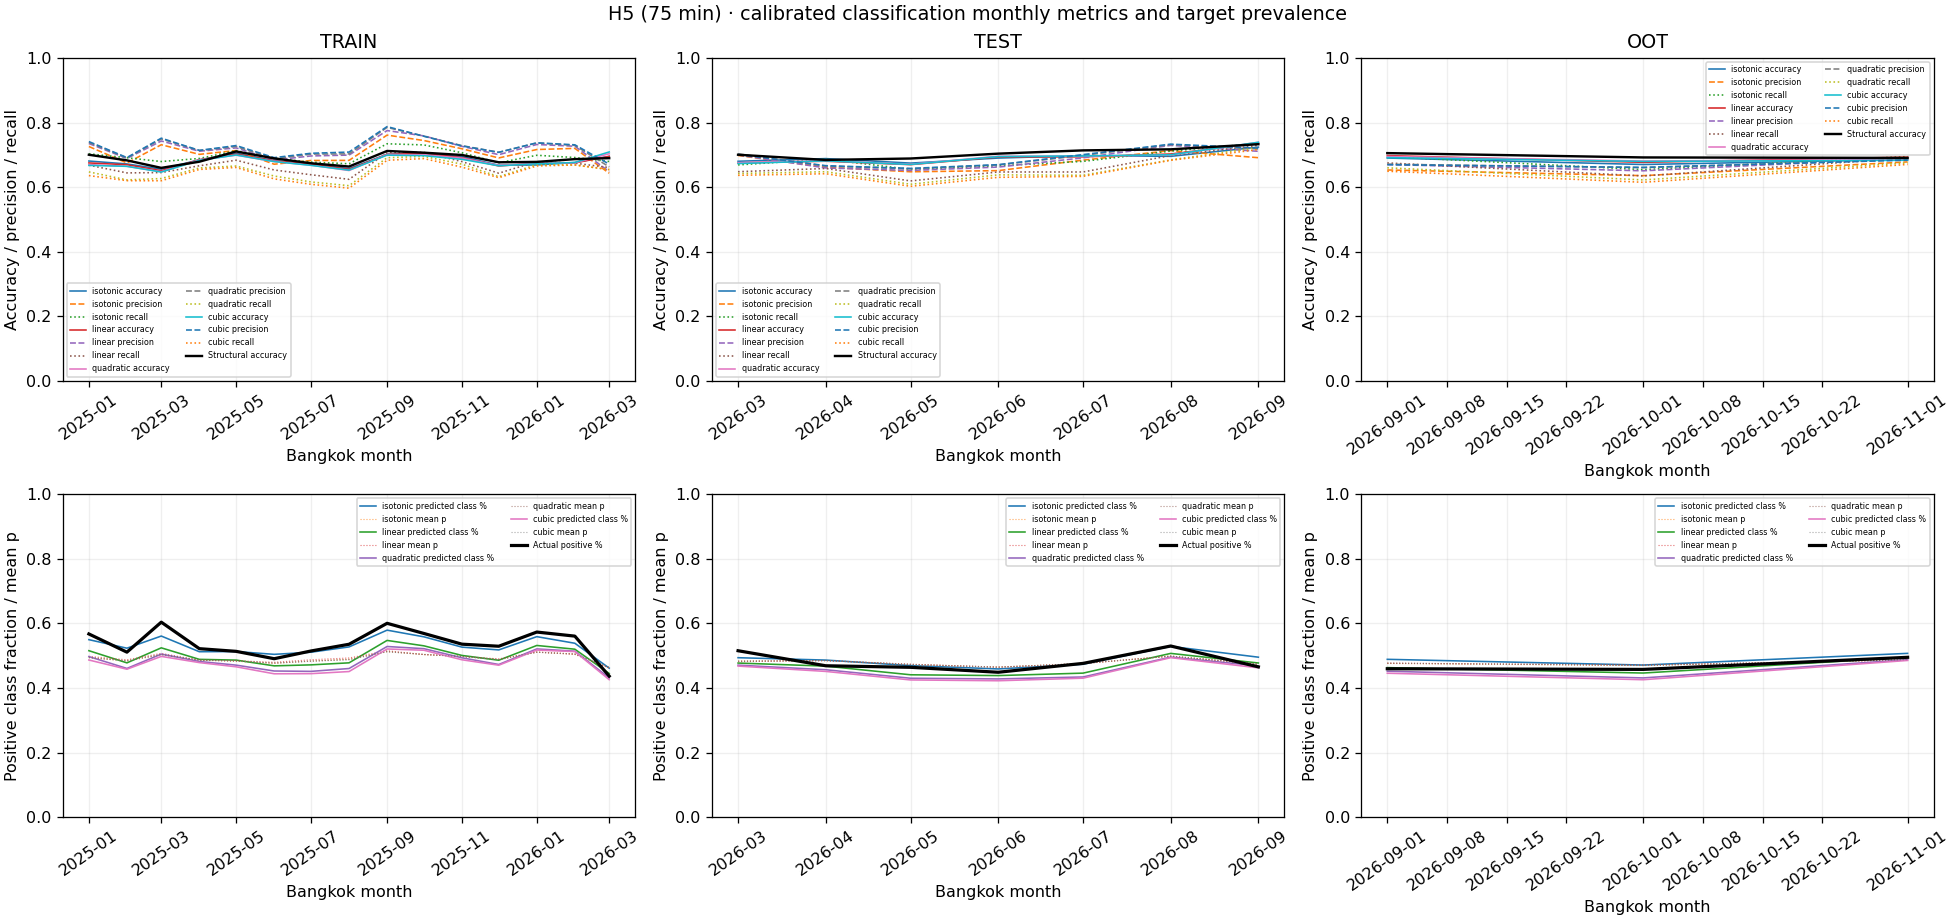

In [9]:
for name in ['raw_regression','raw_classification','calibration','calibrated_regression','calibrated_classification']:
    print(name)
    display(Image(filename=str(P/f'plots/h5_{name}.png')))

## Conclusion
The models meet gain-diversity and declared historical stability rules. No compact base model had a positive lower paired OOT improvement bound versus structural persistence. Calibration changes probabilities and price mapping; it cannot supply missing future information. Confirm predictive claims on genuinely new prospective data.